<h1 style="font-weight:900; color:#0E2841; color:var(--vscode-foreground, #0E2841); margin:0.4em 0 0.2em; overflow:hidden;"><span style="float:right"><span class="modulchip" style="font-size:0.55em; font-weight:bold; letter-spacing:0.02em; border:1.5px solid #B8860B; color:#B8860B; padding:1px 8px; border-radius:10px; margin-left:12px; vertical-align:0.35em; white-space:nowrap;">M2 · Data-Science-Werkzeugkasten</span></span>Lerneinheit 4 · pandas und Matplotlib: der Datenworkflow</h1>

<div style="font-size:0.8em; color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); margin-top:-4px;">Version 1.0</div>

<span style="color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); font-size:0.9em;">Tensor to GPU – Programmierkonzepte für KI · Prof. Dr. Stephan Kurpjuweit · Hochschule Worms · © 2026</span>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Lernziele</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Nach dieser Lerneinheit können Sie …</p>
<ul style="list-style:none; padding-left:0.2em; margin:6px 0 0;">
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>eine CSV-Datei in einen DataFrame einlesen und die Datentypen und fehlenden Werte prüfen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>erklären, woraus eine Spalte eines DataFrames besteht und wie sie zum NumPy-Array wird,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>Zeilen und Spalten mit Masken, <code style="color:inherit;">loc</code> und <code style="color:inherit;">iloc</code> auswählen und den Unterschied zwischen Zuordnung über den Index und über die Position erklären,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>einen Datensatz nach einem festgelegten Vertrag bereinigen und die Bereinigung mit einer Prüfzelle nachweisen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>Werte je Gruppe zusammenfassen und die Wirkung fehlender Werte auf Kennzahlen benennen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>ein Ergebnis mit Matplotlib als beschriftetes Balken-, Histogramm- oder Streudiagramm darstellen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>aus festgelegten Merkmalsspalten ein Array der Form (N, D) mit dem Datentyp <code style="color:inherit;">float32</code> und die Zielspalte getrennt davon erzeugen.</li>
</ul>

</div>
</div>

In den ersten drei Lerneinheiten waren die Daten Vektoren und Tensoren: Zahlenblöcke gleicher Art, auf denen NumPy rechnet. Die meisten Daten, mit denen ein Modell später trainiert wird, sehen anders aus. Sie kommen als Tabelle, mit einer Zeile je Beobachtung und Spalten verschiedener Art: Zahlen, Text, Kategorien. Dazu kommen Probleme mit der Datenqualität, etwa fehlende Werte, falsche Werte und uneinheitliche Schreibweisen. Bevor aus einer solchen Tabelle ein Tensor wird, muss sie eingelesen, geprüft, bereinigt und verstanden werden. Diesen Ablauf nennen wir Datenworkflow. pandas ist eine der Standardbibliotheken dafür, Matplotlib stellt die Ergebnisse grafisch dar.

Mit dieser Lerneinheit beginnt eine Folge von drei Lerneinheiten, die mit dem Training eines kleinen Modells endet: In dieser Lerneinheit entsteht aus einer unsauberen Datei eine bereinigte Tabelle, in der nächsten wird daraus die Eingabe für ein Modell, und danach trainieren wir damit ein neuronales Netz. Der Datensatz dafür ist die Passagierliste der Titanic, ein verbreiteter Lehrdatensatz. Er enthält Zahlen und Kategorien, fehlende Werte und eine Zielspalte, die sich vorhersagen lässt.

Was aus LE03 weitergilt: Ein DataFrame ist eine Sammlung benannter Spalten, und was LE03 über Masken, Achsen und Reduktionen gezeigt hat, gilt hier weiter, nur dass Spalten jetzt Namen haben. Eine Maske wählt Zeilen aus, `groupby` fasst je Gruppe zusammen, und `to_numpy()` ist der Weg zurück zum Array. Neu ist ein Unterschied: pandas ordnet über den Index zu, NumPy über die Position.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Inhalt</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul style="margin:0; padding-left:1.2em;"><li style="margin:5px 0;">4.1&nbsp;&nbsp;<a href="#kap-von-listen-zu-tabellen" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Von Listen zu Tabellen</a></li><li style="margin:5px 0;">4.2&nbsp;&nbsp;<a href="#kap-der-datensatz-und-das-einlesen" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Der Datensatz und das Einlesen</a></li><li style="margin:5px 0;">4.3&nbsp;&nbsp;<a href="#kap-auswaehlen-und-filtern" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Auswählen und Filtern</a></li><li style="margin:5px 0;">4.4&nbsp;&nbsp;<a href="#kap-bereinigen-mit-vertrag" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Bereinigen mit Vertrag</a></li><li style="margin:5px 0;">4.5&nbsp;&nbsp;<a href="#kap-gruppieren-und-zusammenfassen" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Gruppieren und Zusammenfassen</a></li><li style="margin:5px 0;">4.6&nbsp;&nbsp;<a href="#kap-darstellen-mit-matplotlib" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Darstellen mit Matplotlib</a></li><li style="margin:5px 0;">4.7&nbsp;&nbsp;<a href="#kap-von-der-tabelle-zum-array" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Von der Tabelle zum Array</a></li></ul>

</div>
</div>

## <a id="kap-von-listen-zu-tabellen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.1&nbsp;&nbsp;Von Listen zu Tabellen</span>

Die 400 Absätze aus den Kursdaten kennen Sie als Liste von Dicts: jeder Absatz ein Dict mit `id`, `title` und `text`. In Grundkurs Teil 2 haben Sie darauf von Hand gezählt, zum Beispiel die Absätze je Titel. pandas macht aus einer solchen Liste eine Tabelle, und die meisten dieser Fragen lassen sich damit in einer Zeile Code beantworten. Die nächsten beiden Zellen stellen die Daten bereit und richten die Bibliotheken ein, führen Sie beide einfach aus. Die zweite prüft außerdem die pandas-Version: Dieses Notebook ist für pandas 3 geschrieben. Auf einer älteren Umgebung schaltet die Zelle das Verhalten ein, das pandas 3 zum Standard macht (Copy-on-Write, erklärt im Kapitel <a href="#kap-bereinigen-mit-vertrag">4.4</a>), und sagt, was dann anders aussieht.

<div style="break-inside:avoid; page-break-inside:avoid;">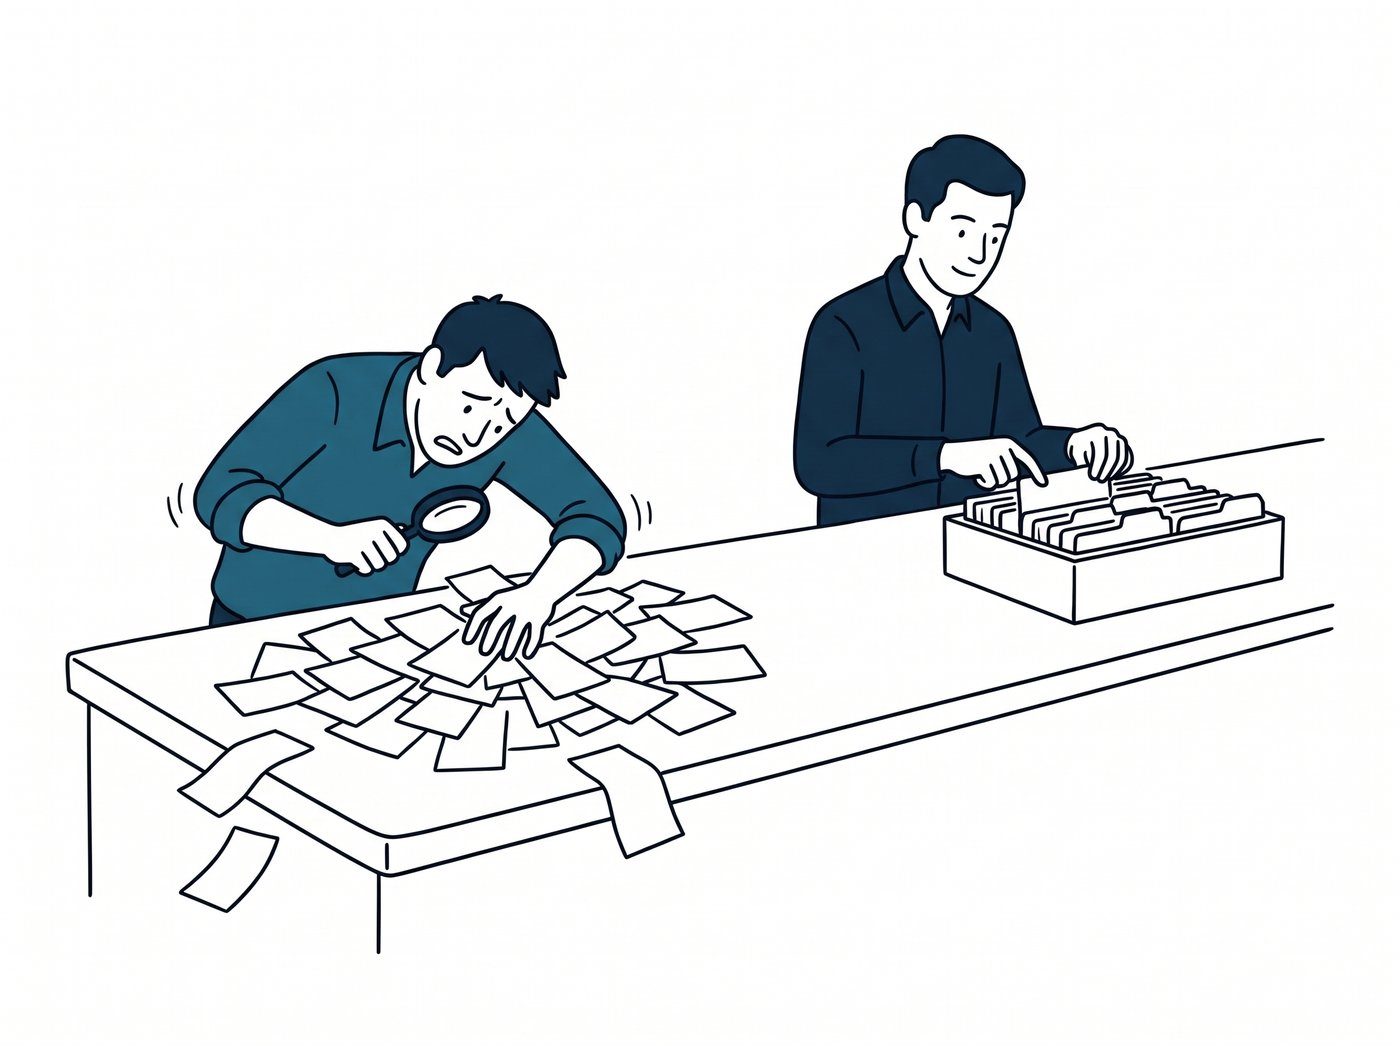<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Eine Liste von Dicts ist der Zettelstapel: Jede Frage heißt alle Zettel durchgehen. Ein DataFrame ist der Karteikasten mit beschrifteten Fächern: Spalten sind direkt ansprechbar, und Fragen wie Filtern oder Zählen sind ein einzelner Aufruf statt einer eigenen Schleife.</div></div>

In [ ]:
# Kursdaten bereitstellen — nutzt data/, lädt Fehlendes aus dem Kursrepo nach
from pathlib import Path
from urllib.request import urlretrieve
for _name in ["appetizer_passages.json", "titanic_raw.csv", "DATENBLATT_titanic.md"]:
    _ziel = Path("data") / _name
    if not _ziel.exists():
        _ziel.parent.mkdir(parents=True, exist_ok=True)
        try:
            urlretrieve("https://raw.githubusercontent.com/skuhswo/tensor-to-gpu-material/main/data/" + _name, _ziel)
        except Exception as _fehler:
            _ziel.unlink(missing_ok=True)          # keine halbe Datei zurücklassen
            _tipp = ""
            if "CERTIFICATE" in str(_fehler):      # Python von python.org auf dem Mac
                _tipp = (" Auf dem Mac zuerst 'Install Certificates.command' im Ordner "
                         "Programme/Python ausführen.")
            if _name.endswith(".md"):               # Datenblatt: Lektüre, kein Pflichtteil
                print(_ziel, "nicht nachgeladen (Datenblatt, nur Lektüre):", type(_fehler).__name__)
                continue
            raise RuntimeError(f"{_ziel} fehlt und ließ sich nicht nachladen ({type(_fehler).__name__}). "
                               "Legen Sie den Ordner data/ aus dem ZIP der Lerneinheit neben dieses Notebook."
                               + _tipp) from None
    print(_ziel, "\u2713")

In [ ]:
# Vorgabe: Bibliotheken und Kursdaten — einfach ausführen
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PANDAS_3 = int(pd.__version__.split(".")[0]) >= 3
if not PANDAS_3:
    pd.options.mode.copy_on_write = True      # ältere pandas-Version: das Verhalten von pandas 3 einschalten
    print(f"pandas {pd.__version__}: Copy-on-Write eingeschaltet; Textspalten erscheinen hier als object statt str")
else:
    print("pandas", pd.__version__)

with open("data/appetizer_passages.json", encoding="utf-8") as f:
    passages = json.load(f)["passages"]       # 400 Absätze als Liste von Dicts
print(len(passages), "Absätze, der erste:", {k: str(v)[:30] for k, v in passages[0].items()})

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: Bibliotheken und Kursdaten — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">json</span><span style="color: #666">,</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">warnings</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">numpy</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">np</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">pd</code> und <code style="color:inherit;">plt</code> sind die üblichen Kurznamen für pandas und das Zeichenmodul von Matplotlib</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">pandas</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">pd</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">matplotlib.pyplot</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">plt</span>

PANDAS_3 <span style="color: #666">=</span> <span style="color: #008000">int</span>(pd<span style="color: #666">.</span>__version__<span style="color: #666">.</span>split(<span style="color: #BA2121">"."</span>)[<span style="color: #666">0</span>]) <span style="color: #666">&gt;=</span> <span style="color: #666">3</span>
<span style="color: #008000; font-weight: bold">if</span> <span style="color: #A2F; font-weight: bold">not</span> PANDAS_3:
    pd<span style="color: #666">.</span>options<span style="color: #666">.</span>mode<span style="color: #666">.</span>copy_on_write <span style="color: #666">=</span> <span style="color: #008000; font-weight: bold">True</span>      <span style="color: #3D7B7B; font-style: italic"># ältere pandas-Version: das Verhalten von pandas 3 einschalten</span>
    <span style="color: #008000">print</span>(<span style="color: #BA2121">f"pandas </span><span style="color: #A45A77; font-weight: bold">{</span>pd<span style="color: #666">.</span>__version__<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: Copy-on-Write eingeschaltet; Textspalten erscheinen hier als object statt str"</span>)
<span style="color: #008000; font-weight: bold">else</span>:
    <span style="color: #008000">print</span>(<span style="color: #BA2121">"pandas"</span>, pd<span style="color: #666">.</span>__version__)

<span style="color: #008000; font-weight: bold">with</span> <span style="color: #008000">open</span>(<span style="color: #BA2121">"data/appetizer_passages.json"</span>, encoding<span style="color: #666">=</span><span style="color: #BA2121">"utf-8"</span>) <span style="color: #008000; font-weight: bold">as</span> f:
    passages <span style="color: #666">=</span> json<span style="color: #666">.</span>load(f)[<span style="color: #BA2121">"passages"</span>]       <span style="color: #3D7B7B; font-style: italic"># 400 Absätze als Liste von Dicts</span>
<span style="color: #008000">print</span>(<span style="color: #008000">len</span>(passages), <span style="color: #BA2121">"Absätze, der erste:"</span>, {k: <span style="color: #008000">str</span>(v)[:<span style="color: #666">30</span>] <span style="color: #008000; font-weight: bold">for</span> k, v <span style="color: #A2F; font-weight: bold">in</span> passages[<span style="color: #666">0</span>]<span style="color: #666">.</span>items()})</code></pre></details>

`pd.DataFrame(liste_von_dicts)` baut aus den Dicts eine Tabelle: Jeder Schlüssel wird eine Spalte, jedes Dict eine Zeile. `head` zeigt die ersten Zeilen, zur Kontrolle, ob die Tabelle so aussieht wie erwartet. Die Attribute daneben beschreiben die Tabelle so, wie `shape` und `dtype` in LE03 ein Array beschrieben haben.

In [ ]:
df_p = pd.DataFrame(passages)
print(df_p.head(3))                 # die ersten drei Zeilen
print()
print("shape:", df_p.shape)          # (Zeilen, Spalten), wie bei einem Array
print("columns:", list(df_p.columns))
print(df_p.dtypes)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">pd.DataFrame(...)</code> nimmt eine Liste von Dicts; die Schlüssel werden Spaltennamen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">df_p <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame(passages)
<span style="color: #008000">print</span>(df_p<span style="color: #666">.</span>head(<span style="color: #666">3</span>))                 <span style="color: #3D7B7B; font-style: italic"># die ersten drei Zeilen</span>
<span style="color: #008000">print</span>()
<span style="color: #008000">print</span>(<span style="color: #BA2121">"shape:"</span>, df_p<span style="color: #666">.</span>shape)          <span style="color: #3D7B7B; font-style: italic"># (Zeilen, Spalten), wie bei einem Array</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"columns:"</span>, <span style="color: #008000">list</span>(df_p<span style="color: #666">.</span>columns))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">dtypes</code> nennt je Spalte den Datentyp: <code style="color:inherit;">int64</code> für die Nummern, <code style="color:inherit;">str</code> für die Texte (unter pandas 3); die letzte Zeile <code style="color:inherit;">dtype: object</code> gehört zur Ausgabe selbst: <code style="color:inherit;">dtypes</code> ist eine Series aus Datentypen, und deren eigener Datentyp ist <code style="color:inherit;">object</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(df_p<span style="color: #666">.</span>dtypes)</code></pre></details>

Für alles, was sich im Kopf nachvollziehen lassen soll, gibt es ab hier eine kleine Tabelle `small` mit fünf Passagieren und drei Spalten; die Grafik unten zeigt dieselben Werte. Die Kursdaten `df_p` und später die Passagierliste bleiben daneben für die echten Fragen.

In [ ]:
small = pd.DataFrame({"pclass": [1, 1, 3, 3, 2],
                      "sex": ["female", "male", "male", "female", "male"],
                      "age": [29.0, 0.75, np.nan, 18.0, 54.0]})
print(small)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; ein Dict aus Spaltenname -&gt; Liste ist die zweite übliche Form, einen DataFrame anzulegen; <code style="color:inherit;">np.nan</code> ist ein fehlender Wert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">small <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"pclass"</span>: [<span style="color: #666">1</span>, <span style="color: #666">1</span>, <span style="color: #666">3</span>, <span style="color: #666">3</span>, <span style="color: #666">2</span>],
                      <span style="color: #BA2121">"sex"</span>: [<span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>, <span style="color: #BA2121">"male"</span>, <span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>],
                      <span style="color: #BA2121">"age"</span>: [<span style="color: #666">29.0</span>, <span style="color: #666">0.75</span>, np<span style="color: #666">.</span>nan, <span style="color: #666">18.0</span>, <span style="color: #666">54.0</span>]})
<span style="color: #008000">print</span>(small)</code></pre></details>

<div style="border-left:5px solid #1F5FB0; background:#EAF1FB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<p><strong>Ein DataFrame ist eine Sammlung benannter Spalten.</strong> Jede Spalte ist eine <code style="color:inherit;">Series</code>: eine Folge von Werten mit genau einem Datentyp. Dazu kommt der Index: die Liste der Zeilenetiketten, ein Etikett je Zeile. Alle Spalten eines DataFrames teilen sich diesen einen Index, deshalb gehört der dritte Eintrag von <code style="color:inherit;">pclass</code> zur selben Zeile wie der dritte Eintrag von <code style="color:inherit;">age</code>.</p>
<p>Standardmäßig sind die Etiketten die Nummern 0 bis N minus 1, die <code style="color:inherit;">pd.DataFrame</code> beim Anlegen vergibt. Es können aber auch Namen oder Datumsangaben sein, und nach einem Filter behalten die übrigen Zeilen ihre alten Nummern. Deshalb heißt es Etikett und nicht Position: Das Etikett bleibt an der Zeile, die Position zählt im Ergebnis neu von 0. In NumPy gibt es nur die Position.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#1F5FB0; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #1F5FB055"><p>Die Werte einer Zahlenspalte liegen als NumPy-Array im Speicher, und <code style="color:inherit;">to_numpy()</code> gibt dieses Array zurück. Textspalten speichert pandas 3 in einem eigenen String-Datentyp; <code style="color:inherit;">to_numpy()</code> stellt auch sie als NumPy-Array bereit. Was Sie über Arrays wissen, gilt deshalb spaltenweise weiter: ein Datentyp je Spalte, Rechenoperationen wirken auf alle Einträge zugleich, und eine Reduktion wie <code style="color:inherit;">sum</code> oder <code style="color:inherit;">mean</code> fasst die Spalte zu einer Zahl zusammen. Das Kapitel <a href="#kap-auswaehlen-und-filtern">4.3</a> zeigt, was aus Etikett und Position folgt. Die Grafik zeigt die Tabelle <code style="color:inherit;">small</code>; ihre drei Spalten nehmen den Datensatz aus Kapitel <a href="#kap-der-datensatz-und-das-einlesen">4.2</a> vorweg.</p></div></details>
</div>

 Array (5,), float64" style="display:block; margin:14px auto; max-width:100%;">

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">df_p["title"]</code> und <code style="color:inherit;">df_p[["title"]]</code> sehen fast gleich aus. Was ist der Unterschied im Ergebnis?</p>

</div>

In [ ]:
print(type(df_p["title"]).__name__, df_p["title"].shape)       # eine Series, Form (400,)
print(type(df_p[["title"]]).__name__, df_p[["title"]].shape)   # ein DataFrame, Form (400, 1)

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.1 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle enthält fünf Zeilen auf der Tabelle <code style="color:inherit;">small</code>. Schreiben Sie für jede Zeile Ihre Vorhersage hinter das <code style="color:inherit;"># -&gt;</code> (Werte, Form oder Typ, so genau Sie können), dann führen Sie die Zelle aus und vergleichen. Wo die Vorhersage danebenlag, ändern Sie die Zeile ab und probieren weiter; dafür ist die Zelle da.</p>

</div>
</div>

In [ ]:
print(small.shape)                      # -> ?
print(small["age"])                     # -> ?
print(small[["pclass", "age"]].shape)   # -> ?
print(small["sex"].value_counts())      # -> ?
print(small["pclass"].sum())            # -> ?

Der Unterschied in einem Satz: Eine `Series` ist eine einzelne Spalte, eindimensional wie ein Vektor, mit einem Datentyp und dem Index. Ein DataFrame ist die Tabelle aus solchen Spalten, zweidimensional, mit einem Datentyp je Spalte und einem Index für alle. Spaltenmethoden wie `value_counts`, `mean` oder `.str.len()` rufen Sie auf einer Series auf, `head`, `shape` und `dtypes` gibt es für beide.

Die nächste Zelle beantwortet drei Fragen aus Grundkurs Teil 2 in je einer Zeile. `value_counts` zählt, wie oft jeder Wert in einer Spalte vorkommt, und sortiert dabei absteigend. Das ist die Zuordnung von Titeln zu Absätzen, die Sie dort mit einem Dict und einer Schleife gebaut haben. Über `.str` erreichen Sie die Textmethoden einer Spalte: `df_p["text"].str.len()` wendet `len` auf jede Zelle an und liefert die Textlänge je Absatz als neue Spalte, ohne Schleife. `describe` fasst eine Zahlenspalte mit Anzahl, Mittelwert, Streuung und Quantilen zusammen.

In [ ]:
counts = df_p["title"].value_counts()
print(counts.head(5))
print("verschiedene Titel:", len(counts))
lengths = df_p["text"].str.len()
print(lengths.describe().round(1))
arr = lengths.to_numpy()
print(type(arr).__name__, arr.shape, arr.dtype, "Mittelwert mit NumPy:", arr.mean().round(1))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">value_counts()</code> liefert eine Series: Index = die Werte, Einträge = ihre Häufigkeit, absteigend sortiert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">counts <span style="color: #666">=</span> df_p[<span style="color: #BA2121">"title"</span>]<span style="color: #666">.</span>value_counts()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; die Ausgabe einer Series endet mit <code style="color:inherit;">Name:</code> und <code style="color:inherit;">dtype:</code>, dem Namen der Series (hier <code style="color:inherit;">count</code>) und ihrem Datentyp; darüber steht <code style="color:inherit;">title</code>, der Name ihres Index</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(counts<span style="color: #666">.</span>head(<span style="color: #666">5</span>))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"verschiedene Titel:"</span>, <span style="color: #008000">len</span>(counts))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">.str.len()</code> wendet <code style="color:inherit;">len</code> auf jede Zelle der Textspalte an und liefert eine Zahlenspalte</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">lengths <span style="color: #666">=</span> df_p[<span style="color: #BA2121">"text"</span>]<span style="color: #666">.</span>str<span style="color: #666">.</span>len()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">describe()</code> fasst eine Zahlenspalte mit Anzahl, Mittelwert, Standardabweichung, Minimum, Quartilen und Maximum zusammen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(lengths<span style="color: #666">.</span>describe()<span style="color: #666">.</span>round(<span style="color: #666">1</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>⑤</b>&nbsp; <code style="color:inherit;">to_numpy()</code> gibt die Werte der Spalte als NumPy-Array zurück, wie Sie es aus LE03 kennen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">arr <span style="color: #666">=</span> lengths<span style="color: #666">.</span>to_numpy()
<span style="color: #008000">print</span>(<span style="color: #008000">type</span>(arr)<span style="color: #666">.</span><span style="color: #19177C">__name__</span>, arr<span style="color: #666">.</span>shape, arr<span style="color: #666">.</span>dtype, <span style="color: #BA2121">"Mittelwert mit NumPy:"</span>, arr<span style="color: #666">.</span>mean()<span style="color: #666">.</span>round(<span style="color: #666">1</span>))</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">3 min</span>✏️ Aufgabe 4.1 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">frequent_titles(df, n)</code>. Sie bekommt den DataFrame der Absätze und eine Zahl <code style="color:inherit;">n</code> und gibt die Liste aller Titel zurück, die mindestens <code style="color:inherit;">n</code> Absätze haben, alphabetisch sortiert. Für <code style="color:inherit;">n = 5</code> sind das neun Titel. Die Prüfzelle vergleicht die Liste. Wie in den früheren Lerneinheiten steht in der Aufgabenzelle der Platzhalter <code style="color:inherit;">...</code> dort, wo Ihr Code hinkommt.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">counts[counts &gt;= n]</code> wählt aus der Series <code style="color:inherit;">counts</code> die Einträge ab <code style="color:inherit;">n</code> aus, so wie eine Maske in LE03 aus einem Array auswählt. Die Titel stehen dann im Index: <code style="color:inherit;">.index</code> liefert sie, <code style="color:inherit;">sorted(...)</code> ordnet sie.</p></div></details>
</div>
</div>

In [ ]:
def frequent_titles(df, n):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
from collections import Counter
result = frequent_titles(df_p, 5)
assert result is not None, "frequent_titles gibt noch nichts zurück (return vergessen?)"
assert isinstance(result, list), "das Ergebnis soll eine Liste sein"
assert len(result) == 9, f"für n = 5 sind es 9 Titel, nicht {len(result)}"
assert result == sorted(result), "die Liste soll alphabetisch sortiert sein"
counted = Counter(p["title"] for p in passages)                       # Vergleichswert ohne pandas, wie in Grundkurs Teil 2
assert result == sorted(t for t, c in counted.items() if c >= 5), "die Liste stimmt nicht mit der Zählung über die Dicts überein"
assert frequent_titles(df_p, 6) == ["Aufklärung", "Mexiko-Stadt"], "für n = 6 bleiben zwei Titel"
tiny = pd.DataFrame({"title": ["B", "A", "B", "A", "B", "C"]})       # zweite Tabelle: die Funktion muss df verwenden, nicht df_p
assert frequent_titles(tiny, 2) == ["A", "B"] and frequent_titles(tiny, 3) == ["B"], "die Funktion soll mit der übergebenen Tabelle df rechnen"
print("n = 5:", result)
print("n = 6:", frequent_titles(df_p, 6))
print("Alle Prüfungen bestanden ✓")

## <a id="kap-der-datensatz-und-das-einlesen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.2&nbsp;&nbsp;Der Datensatz und das Einlesen</span>

Für die nächsten Lerneinheiten brauchen wir einen anderen Datensatz als die Suchdaten: eine Tabelle mit Zahlen, Kategorien und Lücken und mit einer Zielspalte, die ein Modell vorhersagen kann. Der Titanic-Datensatz ist dafür ein klassischer Lehrdatensatz: eine Zeile je Passagier mit Klasse, Geschlecht, Alter, Fahrpreis und weiteren Angaben, dazu die Spalte `survived` mit 1 für überlebt und 0 für nicht überlebt. Er stammt von der Vanderbilt University (Harrell und Cason, zusammengestellt aus der Encyclopedia Titanica), liegt auf OpenML, einer offenen Plattform für Lehr- und Forschungsdatensätze, unter der Nummer 40945 und ist dort als „Public" freigegeben. Das Beispiel „Column Transformer with Mixed Types" aus der scikit-learn-Dokumentation, das die nächste Lerneinheit als Vorlage nimmt, verwendet denselben Datensatz (Link im Quellenblock).

Die Kursfassung `titanic_raw.csv` enthält dieselben Daten mit absichtlich eingebauten Problemen, wie sie in echten Daten vorkommen. Welche das sind, steht im Datenblatt `DATENBLATT_titanic.md`, das die Ladezelle zusammen mit der CSV-Datei nach `data/` legt. Die folgende Übersicht nennt zu jeder Spalte ihre Bedeutung, die Art ihrer Werte und ihre Rolle für das spätere Modell:

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Die Spalten des Datensatzes</span></div>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:14%"><col><col style="width:16%"><col style="width:20%"></colgroup>
<thead>
<tr>
<th>Spalte</th>
<th>Bedeutung</th>
<th>Art</th>
<th>Rolle</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">pclass</code></td>
<td>Klasse der Fahrkarte, 1 bis 3</td>
<td>Kategorie als Zahl</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">survived</code></td>
<td>1 überlebt, 0 nicht überlebt</td>
<td>Zahl 0/1</td>
<td>Zielgröße</td>
</tr>
<tr>
<td><code style="color:inherit;">name</code></td>
<td>Name mit Anrede</td>
<td>Text</td>
<td>bleibt, kein Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">sex</code></td>
<td>Geschlecht, <code style="color:inherit;">female</code> oder <code style="color:inherit;">male</code></td>
<td>Kategorie</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">age</code></td>
<td>Alter in Jahren, bei Kindern mit Nachkommastellen</td>
<td>Zahl, Lücken</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">sibsp</code></td>
<td>Anzahl Geschwister und Ehepartner an Bord</td>
<td>Zahl</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">parch</code></td>
<td>Anzahl Eltern und Kinder an Bord</td>
<td>Zahl</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">ticket</code></td>
<td>Fahrkartennummer</td>
<td>Text</td>
<td>bleibt, kein Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">fare</code></td>
<td>Fahrpreis in Pfund</td>
<td>Zahl, Lücken</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">cabin</code></td>
<td>Kabinennummer</td>
<td>Text, viele Lücken</td>
<td>bleibt, kein Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">embarked</code></td>
<td>Hafen: <code style="color:inherit;">C</code> Cherbourg, <code style="color:inherit;">Q</code> Queenstown, <code style="color:inherit;">S</code> Southampton</td>
<td>Kategorie, Lücken</td>
<td>Merkmal</td>
</tr>
<tr>
<td><code style="color:inherit;">boat</code></td>
<td>Nummer des Rettungsboots</td>
<td>Text, Lücken</td>
<td>wird entfernt (Leakage)</td>
</tr>
<tr>
<td><code style="color:inherit;">body</code></td>
<td>Nummer bei Bergung der Leiche</td>
<td>Zahl, Lücken</td>
<td>wird entfernt (Leakage)</td>
</tr>
<tr>
<td><code style="color:inherit;">home.dest</code></td>
<td>Wohnort und Reiseziel</td>
<td>Text, Lücken</td>
<td>wird entfernt</td>
</tr>
</tbody>
</table>
<p>Merkmale sind die Spalten, aus denen ein Modell später die Zielgröße vorhersagen soll; die Zielgröße ist, was vorhergesagt wird. „Lücken" heißt: In manchen Zeilen fehlt der Wert. <code style="color:inherit;">boat</code> und <code style="color:inherit;">body</code> entstehen erst nach dem Unglück, mit der Rettung und der Bergung, und verraten das Ergebnis fast vollständig: Wer in einem Rettungsboot saß, hat in der Regel überlebt, wessen Leiche geborgen wurde, nicht. Zu dem Zeitpunkt, für den ein Modell vorhersagen soll, gibt es diese Angaben noch nicht. Ein Modell, das sie im Training sieht, lernt die Antwort auswendig statt den Zusammenhang mit Klasse, Alter und Geschlecht, und beim Einsatz fehlen sie. Das heißt Leakage, deshalb werden beide Spalten im Bereinigungskapitel entfernt. (Ausnahmslos ist die Regel nicht: Neun Passagiere haben eine Bootsangabe und trotzdem <code style="color:inherit;">survived == 0</code>. Nach der Encyclopedia Titanica erreichten sie ein Boot und starben trotzdem, die meisten in den überfluteten Faltbooten A und B.) <code style="color:inherit;">home.dest</code> ist Freitext, den dieses Kursmodell nicht aufbereitet, und wird ebenfalls entfernt. <code style="color:inherit;">name</code>, <code style="color:inherit;">ticket</code> und <code style="color:inherit;">cabin</code> bleiben in der Tabelle, weil sie Passagiere identifizieren und später beim Prüfen helfen, sie werden aber nicht als Merkmal verwendet.</p>

</div>

`pd.read_csv` liest eine Textdatei mit Komma als Trennzeichen und erkennt für jede Spalte selbst einen Datentyp. Mit den Standardeinstellungen führt das bei unseren Spalten zu: nur ganze Zahlen wird `int64`, Zahlen mit Nachkommastellen `float64`, und eine Spalte, in der auch nur ein Eintrag keine Zahl ist, wird Text. (Wahrheitswerte erkennt `read_csv` ebenfalls, in diesem Datensatz kommen sie nicht vor.) `encoding="utf-8"` legt fest, wie die Umlaute in der Datei zu lesen sind, wie bei `open` in den Ladezellen der früheren Lerneinheiten. Die nächste Zelle liest die Kursfassung ohne weitere Angaben ein und zeigt, was dabei herauskommt.

In [ ]:
raw = pd.read_csv("data/titanic_raw.csv", encoding="utf-8")
print(raw.shape)
print(raw.iloc[:3, :6])
print()
raw.info()

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">pd.read_csv(pfad)</code> liest die Datei und liefert einen DataFrame; die erste Zeile der Datei wird zu den Spaltennamen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">raw <span style="color: #666">=</span> pd<span style="color: #666">.</span>read_csv(<span style="color: #BA2121">"data/titanic_raw.csv"</span>, encoding<span style="color: #666">=</span><span style="color: #BA2121">"utf-8"</span>)
<span style="color: #008000">print</span>(raw<span style="color: #666">.</span>shape)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">iloc[:3, :6]</code> wählt nach Position: die ersten drei Zeilen und die ersten sechs Spalten (Kapitel <a href="#kap-auswaehlen-und-filtern">4.3</a>)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(raw<span style="color: #666">.</span>iloc[:<span style="color: #666">3</span>, :<span style="color: #666">6</span>])
<span style="color: #008000">print</span>()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">info()</code> zeigt je Spalte die Anzahl der vorhandenen Werte und den Datentyp</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">raw<span style="color: #666">.</span>info()</code></pre></details>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche Spalten müssen Zahlen sein, damit sich damit rechnen lässt? Welche davon sind es nach dem Einlesen nicht, und woran könnte das liegen?</p>

</div>

In [ ]:
print(list(raw.columns))                              # zwei Namen mit Leerzeichen
print(raw[" age"].head(6).tolist())                   # Zahlen, aber als Text (Anführungszeichen)
print(raw.loc[raw[" age"] == "?", " age"].head(3).tolist())   # und so sehen die fehlenden Werte aus
print("Einträge mit ?:", (raw[" age"] == "?").sum(), "in age,", (raw["fare "] == "?").sum(), "in fare")

Zwei Angaben an `read_csv` beheben beides. `na_values=["?"]` sagt, dass `?` ein fehlender Wert ist. Die Spalte enthält dann nur noch Zahlen und Lücken und wird `float64`. Die Lücken selbst heißen `NaN` (not a number), ein besonderer Fließkommawert, den auch NumPy kennt. Ein `int64`-Array hat keine Darstellung für „fehlt", `NaN` ist ein Fließkommawert. Deshalb liest `read_csv` eine Zahlenspalte mit Lücken standardmäßig als `float64` ein, auch wenn alle vorhandenen Werte ganze Zahlen sind (die nullable Typen in der Übersicht unten wären die Alternative, wir verwenden sie nicht). Die Leerzeichen in den Spaltennamen entfernt `columns.str.strip()`, dieselbe Textmethode wie bei den Wörtern in Grundkurs Teil 2, hier auf die Namen angewendet.

In [ ]:
raw2 = pd.read_csv("data/titanic_raw.csv", encoding="utf-8", na_values=["?"])
raw2.columns = raw2.columns.str.strip()
print(raw2.dtypes)
print()
print(raw2.isna().sum())

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">na_values=[...]</code> nennt zusätzliche Zeichenfolgen, die als fehlender Wert gelten; das leere Feld und einige Standardzeichenfolgen wie <code style="color:inherit;">NA</code> gelten mit den Standardeinstellungen ohnehin</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">raw2 <span style="color: #666">=</span> pd<span style="color: #666">.</span>read_csv(<span style="color: #BA2121">"data/titanic_raw.csv"</span>, encoding<span style="color: #666">=</span><span style="color: #BA2121">"utf-8"</span>, na_values<span style="color: #666">=</span>[<span style="color: #BA2121">"?"</span>])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">columns</code> ist eine Folge wie eine Series; <code style="color:inherit;">.str.strip()</code> wirkt auf jeden Namen, die Zuweisung ersetzt die Namen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">raw2<span style="color: #666">.</span>columns <span style="color: #666">=</span> raw2<span style="color: #666">.</span>columns<span style="color: #666">.</span>str<span style="color: #666">.</span>strip()
<span style="color: #008000">print</span>(raw2<span style="color: #666">.</span>dtypes)
<span style="color: #008000">print</span>()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">isna()</code> liefert je Zelle True für fehlend; <code style="color:inherit;">sum()</code> zählt spaltenweise, wie eine Reduktion über Achse 0</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(raw2<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum())</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Fehlende Werte</span></div>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:22%"><col><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Schreibweise</th>
<th>Bedeutung</th>
<th>Wo sie vorkommt</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">NaN</code></td>
<td>not a number, ein Fließkommawert; <code style="color:inherit;">np.nan</code> in NumPy</td>
<td>Zahlenspalten mit Lücken, beim Einlesen <code style="color:inherit;">float64</code></td>
</tr>
<tr>
<td><code style="color:inherit;">None</code></td>
<td>das Python-Objekt für „kein Wert"</td>
<td>in Listen und Dicts; beim Anlegen eines DataFrames daraus wird es zur Lücke</td>
</tr>
<tr>
<td><code style="color:inherit;">pd.NA</code></td>
<td>pandas-eigener Platzhalter für Lücken</td>
<td>nur in den nullable Typen wie <code style="color:inherit;">Int64</code> und <code style="color:inherit;">boolean</code>; in diesem Kurs kommt er nicht vor</td>
</tr>
<tr>
<td><code style="color:inherit;">isna()</code>, <code style="color:inherit;">notna()</code></td>
<td>Maske: Zelle fehlt, Zelle ist vorhanden; erkennt alle drei Schreibweisen</td>
<td>auf Series und DataFrame</td>
</tr>
<tr>
<td><code style="color:inherit;">dropna()</code></td>
<td>Zeilen (oder Spalten) mit Lücken entfernen, als neues Objekt</td>
<td>vor dem Zeichnen, ohne die Gesamttabelle zu ersetzen</td>
</tr>
</tbody>
</table>
<p>In diesem Notebook brauchen Sie nur <code style="color:inherit;">NaN</code>, <code style="color:inherit;">isna</code> und <code style="color:inherit;">dropna</code>. Die nullable Typen wie <code style="color:inherit;">Int64</code> (großes I) erlauben Lücken in einer Spalte, die trotzdem ganzzahlig bleibt; dafür markieren sie die Lücke mit <code style="color:inherit;">pd.NA</code> statt <code style="color:inherit;">NaN</code>, mit eigenen Regeln beim Vergleichen und Rechnen. Wir verwenden sie nicht: scikit-learn und PyTorch erwarten ohnehin Fließkomma-Arrays, <code style="color:inherit;">float64</code> mit <code style="color:inherit;">NaN</code> funktioniert überall gleich, und ein zweiter Platzhalter für Lücken wäre mehr zu lernen ohne Nutzen für diesen Kurs.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Welche Parameter von read_csv braucht man?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">read_csv</code> hat über fünfzig Parameter. In der Praxis genügen meist vier: <code style="color:inherit;">sep</code> für ein anderes Trennzeichen (deutsche Exporte verwenden oft <code style="color:inherit;">;</code>), <code style="color:inherit;">encoding</code>, <code style="color:inherit;">na_values</code> und <code style="color:inherit;">usecols</code> für eine Auswahl der Spalten schon beim Einlesen.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Dazu kommen gelegentlich <code style="color:inherit;">dtype</code>, um einer Spalte den Typ vorzugeben (zum Beispiel eine Postleitzahl als Text, damit führende Nullen bleiben), <code style="color:inherit;">parse_dates</code> für Datumsspalten und <code style="color:inherit;">nrows</code>, um bei einer großen Datei zuerst nur die ersten Zeilen zu lesen. Alles Weitere schlagen Sie nach, wenn eine Datei es verlangt. Die <a href="https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html">Dokumentation von <code style="color:inherit;">read_csv</code></a> zeigt die vollständige Liste.</p>
<p>Steht in einer Zahlenspalte ein Eintrag, den <code style="color:inherit;">na_values</code> nicht kennt (etwa <code style="color:inherit;">unbekannt</code>), bleibt die Spalte Text. <code style="color:inherit;">pd.to_numeric(spalte, errors="coerce")</code> wandelt sie nachträglich um und macht aus jedem Eintrag, der keine Zahl ist, eine Lücke: <code style="color:inherit;">pd.to_numeric(pd.Series(["23", "unbekannt", "41"]), errors="coerce")</code> ergibt <code style="color:inherit;">23.0, NaN, 41.0</code>. Weil dabei aus Fehlern stillschweigend Lücken werden, zählen Sie danach die Lücken mit <code style="color:inherit;">isna().sum()</code> und vergleichen mit vorher. Ohne <code style="color:inherit;">errors="coerce"</code> bricht <code style="color:inherit;">to_numeric</code> beim ersten ungültigen Eintrag mit einem <code style="color:inherit;">ValueError</code> ab, was beim Nachforschen oft hilfreicher ist.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 4.2 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">load_titanic(path)</code>. Sie liest die Datei unter <code style="color:inherit;">path</code> so ein, dass <code style="color:inherit;">age</code> und <code style="color:inherit;">fare</code> den Datentyp <code style="color:inherit;">float64</code> haben und alle Spaltennamen ohne Leerzeichen sind, und gibt den DataFrame zurück. Die Prüfzelle prüft Form, Spaltennamen und Datentypen. Spätere Zellen bauen auf <code style="color:inherit;">load_titanic</code> auf.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Zwei Angaben an <code style="color:inherit;">read_csv</code> und eine Zeile für die Spaltennamen. Das Ergebnis des Aufrufs <code style="color:inherit;">pd.read_csv(...)</code> ist der DataFrame, den Sie zurückgeben.</p></div></details>
</div>
</div>

In [ ]:
def load_titanic(path):
    """Liest die Kursfassung des Titanic-Datensatzes als DataFrame ein."""
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
df = load_titanic("data/titanic_raw.csv")
assert df is not None, "load_titanic gibt noch nichts zurück (return vergessen?)"
assert df.shape == (1321, 14), f"die Kursfassung hat 1321 Zeilen und 14 Spalten, nicht {df.shape}"
assert list(df.columns)[:5] == ["pclass", "survived", "name", "sex", "age"], "Spaltennamen ohne Leerzeichen erwartet"
assert df["age"].dtype == "float64" and df["fare"].dtype == "float64", "age und fare sollen float64 sein (na_values)"
assert df["age"].isna().sum() == 264, "264 fehlende Alterswerte erwartet (263 im Original plus eins in den doppelten Zeilen)"
import os, tempfile                                     # zweite Datei: die Funktion muss den übergebenen Pfad lesen
tiny_path = os.path.join(tempfile.gettempdir(), "titanic_tiny.csv")
with open(tiny_path, "w", encoding="utf-8") as f:
    f.write("pclass, age\n1,?\n2,3.5\n")
tiny = load_titanic(tiny_path)
assert tiny.shape == (2, 2) and list(tiny.columns) == ["pclass", "age"], "load_titanic soll die Datei unter path lesen und die Namen bereinigen"
assert tiny["age"].dtype == "float64" and tiny["age"].isna().sum() == 1, "auch in der kleinen Datei soll ? zur Lücke werden"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu load_titanic</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def load_titanic(path):&#10;    &quot;&quot;&quot;Liest die Kursfassung des Titanic-Datensatzes als DataFrame ein.&quot;&quot;&quot;&#10;    df = pd.read_csv(path, encoding=&quot;utf-8&quot;, na_values=[&quot;?&quot;])   # &quot;?&quot; als fehlender Wert&#10;    df.columns = df.columns.str.strip()                         # Leerzeichen aus den Spaltennamen&#10;    return df</pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Einlesen und Überblick gewinnen</span></div>
<p>Die Ergebnisse gelten für die kleine Tabelle <code style="color:inherit;">small</code>; auf den Kursdaten stehen dieselben Aufrufe in den Zellen oben.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>CSV-Datei lesen</td>
<td><code style="color:inherit;">pd.read_csv(pfad, encoding="utf-8")</code></td>
<td>DataFrame</td>
</tr>
<tr>
<td><code style="color:inherit;">?</code> als Lücke lesen</td>
<td><code style="color:inherit;">pd.read_csv(pfad, na_values=["?"])</code></td>
<td>Spalte wird <code style="color:inherit;">float64</code> statt Text</td>
</tr>
<tr>
<td>Leerzeichen aus Spaltennamen</td>
<td><code style="color:inherit;">df.columns = df.columns.str.strip()</code></td>
<td>ändert die Namen</td>
</tr>
<tr>
<td>erste Zeilen ansehen</td>
<td><code style="color:inherit;">small.head(3)</code></td>
<td>die ersten drei Zeilen</td>
</tr>
<tr>
<td>Form</td>
<td><code style="color:inherit;">small.shape</code></td>
<td><code style="color:inherit;">(5, 3)</code></td>
</tr>
<tr>
<td>Typ je Spalte</td>
<td><code style="color:inherit;">small.dtypes</code></td>
<td><code style="color:inherit;">int64</code>, <code style="color:inherit;">str</code>, <code style="color:inherit;">float64</code></td>
</tr>
<tr>
<td>Anzahl und Typ je Spalte</td>
<td><code style="color:inherit;">small.info()</code></td>
<td>Übersicht mit Lücken</td>
</tr>
<tr>
<td>Kennzahlen einer Zahlenspalte</td>
<td><code style="color:inherit;">small["age"].describe()</code></td>
<td>Anzahl 4, Mittelwert 25.44, …</td>
</tr>
<tr>
<td>Lücken je Spalte</td>
<td><code style="color:inherit;">small.isna().sum()</code></td>
<td><code style="color:inherit;">age 1</code>, sonst 0</td>
</tr>
</tbody>
</table>
<p><strong>Falle:</strong> Steht in einer Zahlenspalte ein <code style="color:inherit;">?</code> oder ein Wort, liest <code style="color:inherit;">read_csv</code> die ganze Spalte als Text. <code style="color:inherit;">na_values</code> oder <code style="color:inherit;">pd.to_numeric(s, errors="coerce")</code> beheben das.</p>

</div>

## <a id="kap-auswaehlen-und-filtern"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.3&nbsp;&nbsp;Auswählen und Filtern</span>

Für die Bereinigung und die Auswertung der Daten müssen Sie oft Teile der Tabelle auswählen: eine Spalte, mehrere Spalten oder die Zeilen, die eine Bedingung erfüllen. Die Maske aus LE03 funktioniert hier genauso, nur mit Spaltennamen statt Achsen. Wie in LE03 üben wir zuerst an der kleinen Tabelle `small` mit bekannten Werten und gehen dann zu den Kursdaten. Die Grafik unten verwendet dieselben fünf Passagiere.

In [ ]:
print(small)                              # die kleine Tabelle aus Kapitel 4.1
print()
mask = small["pclass"] == 3
print(mask.tolist())
print(small[mask])

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(small)                              <span style="color: #3D7B7B; font-style: italic"># die kleine Tabelle aus Kapitel 4.1</span>
<span style="color: #008000">print</span>()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; ein Vergleich mit einer Spalte liefert eine Series aus True und False: die Maske</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">mask <span style="color: #666">=</span> small[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> <span style="color: #666">3</span>
<span style="color: #008000">print</span>(mask<span style="color: #666">.</span>tolist())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">df[maske]</code> behält die Zeilen, bei denen die Maske True ist; der Index der Zeilen bleibt erhalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(small[mask])</code></pre></details>

Die Maske sieht aus wie in LE03, und für Bedingungen gelten dieselben Regeln: `&` für und, `|` für oder, `~` für nicht, und jede Teilbedingung in Klammern, weil `&` stärker bindet als `==`. Ein Unterschied steckt im Ergebnis: Die Zeilen 2 und 3 behalten ihre Etiketten, also ihre Einträge im Index, hier die Nummern, die `pd.DataFrame` vergeben hat (es könnten auch Namen oder Datumsangaben sein). In NumPy wäre die erste Zeile des Ergebnisses einfach die Zeile 0. In pandas hat sie das Etikett 2 und die Position 0, und beides lässt sich ansprechen: `loc` wählt nach dem Etikett, `iloc` nach der Position.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">sub = small[small["pclass"] == 3]</code> enthält die Zeilen mit den Etiketten 2 und 3. Was liefert <code style="color:inherit;">sub.iloc[0]</code>, was <code style="color:inherit;">sub.loc[0]</code>?</p>

</div>

In [ ]:
sub = small[small["pclass"] == 3]
print("loc[2]:"); print(sub.loc[2])
print("iloc[0]:"); print(sub.iloc[0])
print("loc[mask, 'age']:", small.loc[small["sex"] == "female", "age"].tolist())
print(small.iloc[0:2, 0:2])

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">sub <span style="color: #666">=</span> small[small[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> <span style="color: #666">3</span>]</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">loc[etikett]</code> wählt die Zeile mit diesem Index-Etikett, <code style="color:inherit;">iloc[position]</code> die Zeile an dieser Position</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"loc[2]:"</span>); <span style="color: #008000">print</span>(sub<span style="color: #666">.</span>loc[<span style="color: #666">2</span>])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"iloc[0]:"</span>); <span style="color: #008000">print</span>(sub<span style="color: #666">.</span>iloc[<span style="color: #666">0</span>])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">loc[zeilen, spalten]</code> nimmt für beide Achsen Etiketten oder Masken, auch kombiniert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"loc[mask, 'age']:"</span>, small<span style="color: #666">.</span>loc[small[<span style="color: #BA2121">"sex"</span>] <span style="color: #666">==</span> <span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>tolist())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">iloc</code> nimmt Positionen wie ein Array: Zeilen 0 bis 1, Spalten 0 bis 1</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(small<span style="color: #666">.</span>iloc[<span style="color: #666">0</span>:<span style="color: #666">2</span>, <span style="color: #666">0</span>:<span style="color: #666">2</span>])</code></pre></details>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">small.loc[1:3]</code> und <code style="color:inherit;">small.iloc[1:3]</code>: Wie viele Zeilen liefert jeder der beiden Ausdrücke?</p>

</div>

In [ ]:
print("loc[1:3]: ", small.loc[1:3].index.tolist(), "<- Etiketten, Ende eingeschlossen")
print("iloc[1:3]:", small.iloc[1:3].index.tolist(), "   <- Positionen, Ende ausgeschlossen wie in Python")

Die Zuordnung über den Index gilt auch für die Maske selbst. Eine Maske als `Series` wird nicht nach Position angelegt, sondern nach Etikett: pandas sucht für jede Zeile der Tabelle den Eintrag mit demselben Etikett in der Maske. Ein NumPy-Array als Maske hat keine Etiketten und wird nach Position angelegt. Die nächste Zelle zeigt beides mit einer Maske, deren Index rückwärts läuft. pandas gibt dabei eine Warnung aus, dass es die Maske nach dem Index neu anordnet.

In [ ]:
mask_rev = pd.Series([True, False, False, False, False], index=[4, 3, 2, 1, 0])
print("als Series:", small[mask_rev].index.tolist(), "<- True steht beim Etikett 4")
print("als Array: ", small[mask_rev.to_numpy()].index.tolist(), "<- True steht an Position 0")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; dieselben Werte, aber die Etiketten laufen von 4 bis 0</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">mask_rev <span style="color: #666">=</span> pd<span style="color: #666">.</span>Series([<span style="color: #008000; font-weight: bold">True</span>, <span style="color: #008000; font-weight: bold">False</span>, <span style="color: #008000; font-weight: bold">False</span>, <span style="color: #008000; font-weight: bold">False</span>, <span style="color: #008000; font-weight: bold">False</span>], index<span style="color: #666">=</span>[<span style="color: #666">4</span>, <span style="color: #666">3</span>, <span style="color: #666">2</span>, <span style="color: #666">1</span>, <span style="color: #666">0</span>])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"als Series:"</span>, small[mask_rev]<span style="color: #666">.</span>index<span style="color: #666">.</span>tolist(), <span style="color: #BA2121">"&lt;- True steht beim Etikett 4"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">to_numpy()</code> wirft die Etiketten weg, die Maske gilt dann nach Position</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"als Array: "</span>, small[mask_rev<span style="color: #666">.</span>to_numpy()]<span style="color: #666">.</span>index<span style="color: #666">.</span>tolist(), <span style="color: #BA2121">"&lt;- True steht an Position 0"</span>)</code></pre></details>

Sortieren und die größten Werte: `sort_values` ordnet nach einer Spalte, `nlargest` nimmt direkt die `n` größten. Beide geben ein neues Objekt zurück, die Tabelle bleibt unverändert. Das Beispiel läuft auf den Kursdaten `df` aus der Aufgabe oben.

In [ ]:
print(df.sort_values("fare", ascending=False).head(3)[["name", "pclass", "fare"]])
print(df.nlargest(3, "age")[["name", "age"]])

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">sort_values(&quot;spalte&quot;, ascending=False)</code> ordnet absteigend; <code style="color:inherit;">head(3)</code> zeigt die ersten drei Zeilen des Ergebnisses</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(df<span style="color: #666">.</span>sort_values(<span style="color: #BA2121">"fare"</span>, ascending<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)<span style="color: #666">.</span>head(<span style="color: #666">3</span>)[[<span style="color: #BA2121">"name"</span>, <span style="color: #BA2121">"pclass"</span>, <span style="color: #BA2121">"fare"</span>]])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">nlargest(n, &quot;spalte&quot;)</code> ist die Abkürzung dafür</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(df<span style="color: #666">.</span>nlargest(<span style="color: #666">3</span>, <span style="color: #BA2121">"age"</span>)[[<span style="color: #BA2121">"name"</span>, <span style="color: #BA2121">"age"</span>]])</code></pre></details>

Die beiden größten Alterswerte, 155 und 134 Jahre, sind unmöglich. Sie stehen in der Kursfassung absichtlich. Das Kapitel <a href="#kap-bereinigen-mit-vertrag">4.4</a> setzt sie später auf fehlend.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.3 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Fünf Zeilen auf <code style="color:inherit;">small</code>, diesmal mit Masken, <code style="color:inherit;">loc</code> und <code style="color:inherit;">iloc</code>. Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, ausführen, vergleichen, abwandeln.</p>

</div>
</div>

In [ ]:
sub = small[small["pclass"] == 3]
print((small["pclass"] == 1).tolist())                  # -> ?
print(small[small["sex"] == "female"].index.tolist())   # -> ?
print(sub.loc[3, "age"], sub.iloc[0]["age"])            # -> ?
print(small.loc[1:2, "sex"].tolist())                   # -> ?
print(small.iloc[1:2]["sex"].tolist())                  # -> ?

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.3 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ersetzen Sie in der nächsten Zelle jedes <code style="color:inherit;">...</code> durch einen Ausdruck, keine Funktion. Die Teile a) bis e) arbeiten mit der kleinen Tabelle <code style="color:inherit;">small</code>, deren Ergebnis Sie vorher im Kopf bestimmen können, Teil f) mit den Kursdaten <code style="color:inherit;">df</code>.</p>
<ul>
<li>a) Die Spalte <code style="color:inherit;">age</code> von <code style="color:inherit;">small</code> als Series.</li>
<li>b) Die Spalten <code style="color:inherit;">pclass</code> und <code style="color:inherit;">age</code> von <code style="color:inherit;">small</code> als DataFrame.</li>
<li>c) Alle Zeilen von <code style="color:inherit;">small</code>, die zur dritten Klasse gehören.</li>
<li>d) Das Alter aller Männer in <code style="color:inherit;">small</code>, ausgewählt mit <code style="color:inherit;">loc</code>, einer Maske und dem Spaltennamen.</li>
<li>e) Aus dem Ergebnis von c) die zweite Zeile, nach Position.</li>
<li>f) Wie viele Passagiere in <code style="color:inherit;">df</code> sind jünger als 10 Jahre und reisen in der dritten Klasse? Eine Zahl.</li>
</ul>
<p>Die Prüfzelle meldet je Teil, was noch nicht passt.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> a) und b) sind Spaltenauswahl mit einem Namen oder einer Liste von Namen, c) eine Maske in eckigen Klammern, d) <code style="color:inherit;">small.loc[maske, "age"]</code>, e) <code style="color:inherit;">iloc</code> auf dem Ergebnis von c), f) zwei Teilbedingungen in Klammern mit <code style="color:inherit;">&amp;</code>, dann <code style="color:inherit;">.sum()</code>.</p></div></details>
</div>
</div>

In [ ]:
a = ...   # a) Spalte age von small als Series
b = ...   # b) Spalten pclass und age als DataFrame
c = ...   # c) alle Zeilen der dritten Klasse
d = ...   # d) Alter der Männer (loc, Maske, Spalte)
e = ...   # e) aus c: zweite Zeile nach Position
f = ...   # f) df: Kinder unter 10 in Klasse 3

In [ ]:
# Prüfzelle — einfach ausführen
assert isinstance(a, pd.Series) and a.name == "age" and len(a) == 5, "a) die Spalte age von small ist eine Series mit fünf Werten"
assert isinstance(b, pd.DataFrame) and list(b.columns) == ["pclass", "age"], "b) zwei Spalten: eine Liste von Namen in den eckigen Klammern"
assert isinstance(c, pd.DataFrame) and list(c.index) == [2, 3], "c) die Zeilen mit pclass == 3; sie behalten die Etiketten 2 und 3"
assert isinstance(d, pd.Series) and list(d.index) == [1, 2, 4] and d.name == "age", "d) loc mit Maske und Spalte age: die Alterswerte der Männer, Etiketten 1, 2, 4"
assert isinstance(e, pd.Series) and e.name == 3 and e["age"] == 18.0, "e) c.iloc[1] ist die zweite Zeile von c, das ist die Zeile mit dem Etikett 3"
assert int(f) == 57, f"f) 57 Kinder unter 10 Jahren in der dritten Klasse (roh), nicht {f}"
print("Alle Prüfungen bestanden ✓")

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Was passiert bei <code style="color:inherit;">df[df["pclass"] == 1 &amp; df["age"] &lt; 30]</code>, also ohne Klammern um die Teilbedingungen?</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">4 min</span>✏️ Aufgabe 4.3 #3</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie die Funktion <code style="color:inherit;">young_first_class_women(df)</code>. Sie gibt ein Tupel aus zwei Werten zurück: wie viele Frauen (<code style="color:inherit;">sex == "female"</code>) der ersten Klasse jünger als 30 Jahre sind, und ihr Durchschnittsalter. Die Prüfzelle rechnet auf den rohen Daten <code style="color:inherit;">df</code>. Das Ergebnis ist vorläufig: <code style="color:inherit;">df</code> enthält noch Duplikate und uneinheitliche Schreibweisen, im nächsten Kapitel rechnen Sie dieselbe Funktion auf den bereinigten Daten noch einmal.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Drei Teilbedingungen mit <code style="color:inherit;">&amp;</code>, jede in Klammern. <code style="color:inherit;">mask.sum()</code> zählt die <code style="color:inherit;">True</code>-Einträge, <code style="color:inherit;">df.loc[mask, "age"].mean()</code> ist der Mittelwert der ausgewählten Alterswerte.</p></div></details>
</div>
</div>

In [ ]:
def young_first_class_women(df):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
result = young_first_class_women(df)
assert result is not None, "young_first_class_women gibt noch nichts zurück (return vergessen?)"
count, mean_age = result
assert count == 42, f"auf den rohen Daten sind es 42, nicht {count}"
assert abs(mean_age - 21.21) < 0.01, f"Durchschnittsalter rund 21.21, nicht {mean_age:.2f}"
print(f"vorläufig, auf den rohen Daten: {count} Frauen, Durchschnittsalter {mean_age:.2f}")
print("Alle Prüfungen bestanden ✓")

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Spalten auswählen und Zeilen filtern</span></div>
<p>Alle Ergebnisse an der Tabelle <code style="color:inherit;">small</code> mit den Etiketten 0 bis 4. Jede Zeile liefert ein neues Objekt, <code style="color:inherit;">small</code> bleibt unverändert.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>eine Spalte</td>
<td><code style="color:inherit;">small["age"]</code></td>
<td>Series, Form <code style="color:inherit;">(5,)</code></td>
</tr>
<tr>
<td>eine Spalte als Tabelle</td>
<td><code style="color:inherit;">small[["age"]]</code></td>
<td>DataFrame, Form <code style="color:inherit;">(5, 1)</code></td>
</tr>
<tr>
<td>mehrere Spalten</td>
<td><code style="color:inherit;">small[["pclass", "age"]]</code></td>
<td>DataFrame, Form <code style="color:inherit;">(5, 2)</code></td>
</tr>
<tr>
<td>Maske bilden</td>
<td><code style="color:inherit;">small["pclass"] == 3</code></td>
<td>Series <code style="color:inherit;">False, False, True, True, False</code></td>
</tr>
<tr>
<td>Zeilen auswählen</td>
<td><code style="color:inherit;">small[small["pclass"] == 3]</code></td>
<td>Zeilen mit den Etiketten 2 und 3</td>
</tr>
<tr>
<td>zwei Bedingungen</td>
<td><code style="color:inherit;">erste = small["pclass"] == 1</code><br><code style="color:inherit;">jung = small["age"] &lt; 30</code><br><code style="color:inherit;">small[erste &amp; jung]</code></td>
<td>Zeilen 0 und 1</td>
</tr>
<tr>
<td>oder, nicht</td>
<td><code style="color:inherit;">small[erste | jung]</code>, <code style="color:inherit;">small[~erste]</code></td>
<td>Zeilen 0, 1, 3; Zeilen 2, 3, 4</td>
</tr>
<tr>
<td>Treffer zählen</td>
<td><code style="color:inherit;">(small["sex"] == "male").sum()</code></td>
<td><code style="color:inherit;">3</code></td>
</tr>
<tr>
<td>Maske mit Spalte</td>
<td><code style="color:inherit;">small.loc[small["sex"] == "male", "age"]</code></td>
<td>Series <code style="color:inherit;">0.75, NaN, 54.0</code>, Etiketten 1, 2, 4</td>
</tr>
<tr>
<td>nach Spalte ordnen</td>
<td><code style="color:inherit;">small.sort_values("age", ascending=False)</code></td>
<td>54.0 zuerst, <code style="color:inherit;">NaN</code> zuletzt</td>
</tr>
<tr>
<td>die größten n</td>
<td><code style="color:inherit;">small.nlargest(2, "age")</code></td>
<td>Zeilen 4 und 0</td>
</tr>
</tbody>
</table>
<p><strong>Falle:</strong> <code style="color:inherit;">small[small["pclass"] == 1 &amp; small["age"] &lt; 30]</code> ohne Klammern bricht mit <code style="color:inherit;">TypeError</code> ab, weil <code style="color:inherit;">&amp;</code> stärker bindet als <code style="color:inherit;">==</code> und <code style="color:inherit;">&lt;</code>.</p>

</div>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Etikett gegen Position</span></div>
<p><code style="color:inherit;">loc</code> wählt nach dem Etikett im Index, <code style="color:inherit;">iloc</code> nach der Position. Nach einem Filter unterscheiden sich beide.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>Filterergebnis merken</td>
<td><code style="color:inherit;">sub = small[small["pclass"] == 3]</code></td>
<td>Etiketten 2 und 3</td>
</tr>
<tr>
<td>Zeile nach Etikett</td>
<td><code style="color:inherit;">sub.loc[2]</code></td>
<td>Zeile mit Etikett 2</td>
</tr>
<tr>
<td>Zeile nach Position</td>
<td><code style="color:inherit;">sub.iloc[0]</code></td>
<td>dieselbe Zeile</td>
</tr>
<tr>
<td>fehlendes Etikett</td>
<td><code style="color:inherit;">sub.loc[0]</code></td>
<td><code style="color:inherit;">KeyError</code></td>
</tr>
<tr>
<td>eine Zelle</td>
<td><code style="color:inherit;">small.loc[3, "age"]</code></td>
<td><code style="color:inherit;">18.0</code></td>
</tr>
<tr>
<td>Bereich nach Etikett</td>
<td><code style="color:inherit;">small.loc[1:3]</code></td>
<td>Etiketten 1, 2, 3: drei Zeilen, Ende eingeschlossen</td>
</tr>
<tr>
<td>Bereich nach Position</td>
<td><code style="color:inherit;">small.iloc[1:3]</code></td>
<td>Positionen 1, 2: zwei Zeilen, Ende ausgeschlossen</td>
</tr>
<tr>
<td>neue Etiketten 0 bis N−1</td>
<td><code style="color:inherit;">sub.reset_index(drop=True)</code></td>
<td>liefert Tabelle mit Etiketten 0, 1</td>
</tr>
</tbody>
</table>
<p><strong>Falle:</strong> Eine Maske als Series wird über die Etiketten zugeordnet, nicht über die Reihenfolge; ein NumPy-Array als Maske über die Position.</p>

</div>

## <a id="kap-bereinigen-mit-vertrag"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.4&nbsp;&nbsp;Bereinigen mit Vertrag</span>

Beim Bereinigen legen Sie fest, welche Werte gültig sind, welche Schreibweisen vereinheitlicht und welche Spalten oder Zeilen entfernt werden. Damit diese Entscheidungen nachprüfbar sind, bekommt die bereinigte Tabelle einen Vertrag, so wie der Operator in LE03 einen hatte: eine Liste von Zusicherungen, welche Spalten die Tabelle hat, welchen Datentyp jede Spalte trägt, welche Werte darin zulässig sind und wo Lücken bleiben dürfen. Die Prüfzelle am Ende des Kapitels prüft genau diesen Vertrag.

<div style="border:2px solid #156082; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#156082; font-weight:bold; font-size:1.08em;">Vertrag der bereinigten Tabelle</span></div>
<p><code style="color:inherit;">clean_titanic(df)</code> nimmt den DataFrame aus <code style="color:inherit;">load_titanic</code> und gibt einen neuen DataFrame zurück. Die Eingabe bleibt unverändert. Der Rückgabewert erfüllt:</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:16%"><col style="width:18%"><col style="width:40%"><col></colgroup>
<thead>
<tr>
<th>Spalte</th>
<th>Datentyp</th>
<th>Zulässige Werte</th>
<th>Lücken</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">pclass</code></td>
<td><code style="color:inherit;">int64</code></td>
<td>1, 2, 3</td>
<td>nein</td>
</tr>
<tr>
<td><code style="color:inherit;">survived</code></td>
<td><code style="color:inherit;">int64</code></td>
<td>0, 1</td>
<td>nein</td>
</tr>
<tr>
<td><code style="color:inherit;">name</code>, <code style="color:inherit;">ticket</code></td>
<td><code style="color:inherit;">str</code></td>
<td>beliebig</td>
<td>nein</td>
</tr>
<tr>
<td><code style="color:inherit;">sex</code></td>
<td><code style="color:inherit;">str</code></td>
<td><code style="color:inherit;">female</code>, <code style="color:inherit;">male</code></td>
<td>nein</td>
</tr>
<tr>
<td><code style="color:inherit;">age</code></td>
<td><code style="color:inherit;">float64</code></td>
<td>0 bis 100</td>
<td>ja</td>
</tr>
<tr>
<td><code style="color:inherit;">sibsp</code>, <code style="color:inherit;">parch</code></td>
<td><code style="color:inherit;">int64</code></td>
<td>ab 0</td>
<td>nein</td>
</tr>
<tr>
<td><code style="color:inherit;">fare</code></td>
<td><code style="color:inherit;">float64</code></td>
<td>ab 0</td>
<td>ja</td>
</tr>
<tr>
<td><code style="color:inherit;">embarked</code></td>
<td><code style="color:inherit;">str</code></td>
<td><code style="color:inherit;">C</code>, <code style="color:inherit;">Q</code>, <code style="color:inherit;">S</code></td>
<td>ja</td>
</tr>
<tr>
<td><code style="color:inherit;">cabin</code></td>
<td><code style="color:inherit;">str</code></td>
<td>beliebig</td>
<td>ja</td>
</tr>
</tbody>
</table>
<p>Die Spalten <code style="color:inherit;">boat</code>, <code style="color:inherit;">body</code> und <code style="color:inherit;">home.dest</code> sind entfernt. Es gibt keine doppelten Zeilen. Der Index läuft von 0 bis N minus 1. Fehlende Werte bleiben fehlend, sie werden nicht aufgefüllt. <code style="color:inherit;">str</code> ist der Texttyp von pandas 3; unter älteren Versionen heißt derselbe Typ <code style="color:inherit;">object</code>. Geprüft werden die Werte, nicht der Name des Datentyps.</p>

</div>

Warum die drei Spalten raus müssen, steht in der Spaltenübersicht: `boat` und `body` entstehen erst nach dem Unglück und gäbe es zum Vorhersagezeitpunkt nicht, und `home.dest` ist Freitext, den dieses Kursmodell nicht aufbereitet. Lücken füllen wir hier nicht. Der Wert zum Füllen, etwa der Mittelwert des Alters, wird aus den Daten berechnet. In der nächsten Lerneinheit darf dafür nur der Trainingsteil der Daten verwendet werden, deshalb passiert das Füllen erst dort, in der Pipeline. Hier zählen wir die Lücken und lassen sie stehen.

Die Werkzeuge, jeweils an der kleinen Tabelle oder an einem Ausschnitt der Kursdaten. `str.strip` und `str.lower` kennen Sie aus Grundkurs Teil 2 für einzelne Texte; über `.str` wirken sie hier auf alle Zellen einer Spalte in einem Aufruf, ohne Schleife.

In [ ]:
print(df["sex"].value_counts().to_dict())
print(df["embarked"].value_counts(dropna=False).to_dict())
print(df["sex"].str.strip().str.lower().value_counts().to_dict())
print(small["sex"].replace({"female": "w", "male": "m"}).tolist())
print("Alter über 100:", df.loc[df["age"] > 100, "age"].tolist(), "-> nach mask:", df["age"].mask(df["age"] > 100).max())
print(df.drop(columns=["boat", "body", "home.dest"]).shape)
print("doppelte Zeilen:", df.duplicated().sum(), "-> drop_duplicates:", df.drop_duplicates().shape)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">value_counts()</code> zeigt, welche Schreibweisen vorkommen; <code style="color:inherit;">dropna=False</code> zählt auch die Lücken</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(df[<span style="color: #BA2121">"sex"</span>]<span style="color: #666">.</span>value_counts()<span style="color: #666">.</span>to_dict())
<span style="color: #008000">print</span>(df[<span style="color: #BA2121">"embarked"</span>]<span style="color: #666">.</span>value_counts(dropna<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)<span style="color: #666">.</span>to_dict())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">.str.strip().str.lower()</code> wendet beide Textmethoden auf jede Zelle an und liefert eine neue Series</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(df[<span style="color: #BA2121">"sex"</span>]<span style="color: #666">.</span>str<span style="color: #666">.</span>strip()<span style="color: #666">.</span>str<span style="color: #666">.</span>lower()<span style="color: #666">.</span>value_counts()<span style="color: #666">.</span>to_dict())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">replace({alt: neu})</code> ersetzt einzelne Werte nach einer Zuordnung; hier nur gezeigt, für die Schreibweisen reicht strip und lower</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(small[<span style="color: #BA2121">"sex"</span>]<span style="color: #666">.</span>replace({<span style="color: #BA2121">"female"</span>: <span style="color: #BA2121">"w"</span>, <span style="color: #BA2121">"male"</span>: <span style="color: #BA2121">"m"</span>})<span style="color: #666">.</span>tolist())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">mask(bedingung)</code> ersetzt die Einträge, bei denen die Bedingung True ist, durch NaN (das Gegenstück <code style="color:inherit;">where</code> behält sie)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Alter über 100:"</span>, df<span style="color: #666">.</span>loc[df[<span style="color: #BA2121">"age"</span>] <span style="color: #666">&gt;</span> <span style="color: #666">100</span>, <span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>tolist(), <span style="color: #BA2121">"-&gt; nach mask:"</span>, df[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>mask(df[<span style="color: #BA2121">"age"</span>] <span style="color: #666">&gt;</span> <span style="color: #666">100</span>)<span style="color: #666">.</span>max())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>⑤</b>&nbsp; <code style="color:inherit;">drop(columns=[...])</code> liefert eine neue Tabelle ohne diese Spalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(df<span style="color: #666">.</span>drop(columns<span style="color: #666">=</span>[<span style="color: #BA2121">"boat"</span>, <span style="color: #BA2121">"body"</span>, <span style="color: #BA2121">"home.dest"</span>])<span style="color: #666">.</span>shape)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>⑥</b>&nbsp; <code style="color:inherit;">duplicated()</code> markiert jede Zeile, die genauso schon einmal vorkam; <code style="color:inherit;">drop_duplicates()</code> entfernt sie</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"doppelte Zeilen:"</span>, df<span style="color: #666">.</span>duplicated()<span style="color: #666">.</span>sum(), <span style="color: #BA2121">"-&gt; drop_duplicates:"</span>, df<span style="color: #666">.</span>drop_duplicates()<span style="color: #666">.</span>shape)</code></pre></details>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Die Kursfassung hat zwölf doppelte Zeilen, <code style="color:inherit;">duplicated</code> findet aber nur elf. Erst die Duplikate entfernen und dann die Schreibweisen vereinheitlichen, oder umgekehrt?</p>

</div>

**Zuweisen.** Beim Bereinigen schreiben Sie in die Tabelle, dafür brauchen Sie zwei Formen. `df["age"] = neue_werte` ersetzt die ganze Spalte oder legt eine neue an, auch mit einem anderen Datentyp. `df.loc[mask, "age"] = wert` ändert nur die ausgewählten Zellen. Einen Wert, der nicht in den Datentyp der Spalte passt (etwa `1.5` in eine `int64`-Spalte), weist pandas 3 mit einem `TypeError` ab. Die Ausnahme ist `NaN`: Ein fehlender Wert in einer `int64`-Spalte macht die ganze Spalte `float64`, weil Ganzzahlen keine Lücke kennen (siehe Überblick Fehlende Werte).

Eine dritte Form sieht aus, als würde sie funktionieren, tut es aber nicht: `df[mask]["age"] = wert`. Das ist eine verkettete Zuweisung. `df[mask]` liefert zuerst ein Zwischenergebnis, eine neue Tabelle mit den ausgewählten Zeilen, und die Zuweisung schreibt in dieses Zwischenergebnis, nicht in `df`. In pandas 3 bleibt `df` unverändert, und pandas gibt eine Warnung aus. Der Grund ist die Regel Copy-on-Write, nach der pandas 3 arbeitet: Ein Objekt, das aus einem anderen abgeleitet ist, etwa ein Filterergebnis oder eine herausgegriffene Spalte, verhält sich beim Schreiben wie eine eigene Kopie. Wo sich zwei Objekte dabei Speicher teilen (bei einer herausgegriffenen Spalte zum Beispiel), kopiert pandas vor dem ersten Schreiben, daher der Name; ein Filterergebnis ist oft schon beim Filtern eine Kopie. Für Sie heißt das: Ein Filterergebnis zu verändern verändert nie die Tabelle, aus der es stammt. Wer in `df` schreiben will, schreibt mit `df.loc[mask, "age"] = wert`.

In [ ]:
t = small.copy()
t["age"] = t["age"].astype("float32")
print("Spalte ersetzt:", t["age"].dtype)
t.loc[t["pclass"] == 3, "age"] = 0.0
print("Zellen geändert:", t["age"].tolist(), t["age"].dtype)
t.loc[t["pclass"] == 2, "pclass"] = np.nan
print("NaN in int64-Spalte:", t["pclass"].tolist(), t["pclass"].dtype)
sub = t[t["pclass"] == 1]
sub["age"] = 99.0
print("t nach dem Schreiben in sub:", t["age"].tolist())
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    t[t["pclass"] == 1]["age"] = 99.0
print("verkettet:", t["age"].tolist(), "| Warnung:", type(w[0].message).__name__ if w else "keine")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t <span style="color: #666">=</span> small<span style="color: #666">.</span>copy()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; ganze Spalte ersetzen: der Datentyp darf sich ändern; <code style="color:inherit;">astype(typ)</code> liefert die Spalte mit diesem Datentyp (hier float32 statt float64)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t[<span style="color: #BA2121">"age"</span>] <span style="color: #666">=</span> t[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>astype(<span style="color: #BA2121">"float32"</span>)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Spalte ersetzt:"</span>, t[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; ausgewählte Zellen ändern: <code style="color:inherit;">loc[maske, spalte] = wert</code>, der Datentyp der Spalte bleibt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t<span style="color: #666">.</span>loc[t[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> <span style="color: #666">3</span>, <span style="color: #BA2121">"age"</span>] <span style="color: #666">=</span> <span style="color: #666">0.0</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Zellen geändert:"</span>, t[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>tolist(), t[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; die Ausnahme: ein fehlender Wert in einer int64-Spalte macht die Spalte float64, weil Ganzzahlen keine Lücke kennen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t<span style="color: #666">.</span>loc[t[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> <span style="color: #666">2</span>, <span style="color: #BA2121">"pclass"</span>] <span style="color: #666">=</span> np<span style="color: #666">.</span>nan
<span style="color: #008000">print</span>(<span style="color: #BA2121">"NaN in int64-Spalte:"</span>, t[<span style="color: #BA2121">"pclass"</span>]<span style="color: #666">.</span>tolist(), t[<span style="color: #BA2121">"pclass"</span>]<span style="color: #666">.</span>dtype)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; ein Filterergebnis ist unter Copy-on-Write unabhängig: Schreiben darauf lässt t unverändert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">sub <span style="color: #666">=</span> t[t[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> <span style="color: #666">1</span>]
sub[<span style="color: #BA2121">"age"</span>] <span style="color: #666">=</span> <span style="color: #666">99.0</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"t nach dem Schreiben in sub:"</span>, t[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>tolist())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>⑤</b>&nbsp; die verkettete Zuweisung ändert nichts; <code style="color:inherit;">warnings.catch_warnings</code> fängt die Warnung ab, damit sie hier als Text erscheint</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">with</span> warnings<span style="color: #666">.</span>catch_warnings(record<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>) <span style="color: #008000; font-weight: bold">as</span> w:
    warnings<span style="color: #666">.</span>simplefilter(<span style="color: #BA2121">"always"</span>)
    t[t[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> <span style="color: #666">1</span>][<span style="color: #BA2121">"age"</span>] <span style="color: #666">=</span> <span style="color: #666">99.0</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"verkettet:"</span>, t[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>tolist(), <span style="color: #BA2121">"| Warnung:"</span>, <span style="color: #008000">type</span>(w[<span style="color: #666">0</span>]<span style="color: #666">.</span>message)<span style="color: #666">.</span><span style="color: #19177C">__name__</span> <span style="color: #008000; font-weight: bold">if</span> w <span style="color: #008000; font-weight: bold">else</span> <span style="color: #BA2121">"keine"</span>)</code></pre></details>

Die Zuordnung über den Index gilt auch beim Zuweisen einer Spalte. `df["col"] = series` legt die Werte nicht der Reihe nach ab, sondern sucht für jede Zeile von `df` den Eintrag mit demselben Etikett in der Series. Gleiche Länge heißt also nicht gleiche Reihenfolge. Ein NumPy-Array oder eine Liste hat keine Etiketten und wird nach Position zugewiesen.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">t["rank"] = pd.Series([1, 2, 3, 4, 5], index=[4, 3, 2, 1, 0])</code> auf einer Kopie von <code style="color:inherit;">small</code>: Welchen Wert bekommt die Zeile mit dem Etikett 0? Und bei <code style="color:inherit;">t["rank"] = np.array([1, 2, 3, 4, 5])</code>?</p>

</div>

In [ ]:
t = small.copy()
t["rank"] = pd.Series([1, 2, 3, 4, 5], index=[4, 3, 2, 1, 0])
print("als Series:", t["rank"].tolist())
t["rank"] = np.array([1, 2, 3, 4, 5])
print("als Array: ", t["rank"].tolist())
t["rank"] = pd.Series([1, 2, 3], index=[0, 1, 2])
print("zu kurz:   ", t["rank"].tolist())

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t <span style="color: #666">=</span> small<span style="color: #666">.</span>copy()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; eine Series mit rückwärts laufenden Etiketten: zugewiesen wird über das Etikett, nicht über die Position</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t[<span style="color: #BA2121">"rank"</span>] <span style="color: #666">=</span> pd<span style="color: #666">.</span>Series([<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>, <span style="color: #666">4</span>, <span style="color: #666">5</span>], index<span style="color: #666">=</span>[<span style="color: #666">4</span>, <span style="color: #666">3</span>, <span style="color: #666">2</span>, <span style="color: #666">1</span>, <span style="color: #666">0</span>])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"als Series:"</span>, t[<span style="color: #BA2121">"rank"</span>]<span style="color: #666">.</span>tolist())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; ein Array hat keine Etiketten und füllt die Spalte der Reihe nach</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t[<span style="color: #BA2121">"rank"</span>] <span style="color: #666">=</span> np<span style="color: #666">.</span>array([<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>, <span style="color: #666">4</span>, <span style="color: #666">5</span>])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"als Array: "</span>, t[<span style="color: #BA2121">"rank"</span>]<span style="color: #666">.</span>tolist())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; fehlt ein Etikett in der Series, bleibt die Zelle leer</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t[<span style="color: #BA2121">"rank"</span>] <span style="color: #666">=</span> pd<span style="color: #666">.</span>Series([<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>], index<span style="color: #666">=</span>[<span style="color: #666">0</span>, <span style="color: #666">1</span>, <span style="color: #666">2</span>])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"zu kurz:   "</span>, t[<span style="color: #BA2121">"rank"</span>]<span style="color: #666">.</span>tolist())</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.4 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle arbeitet auf einer Kopie <code style="color:inherit;">t</code> von <code style="color:inherit;">small</code>. Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, ausführen, vergleichen. Die letzte Zeile ist die wichtigste.</p>

</div>
</div>

In [ ]:
t = small.copy()
print(t["sex"].str.upper().tolist()[:2])      # -> ?
print(t["age"].mask(t["age"] < 1).tolist())   # -> ?
t.loc[t["pclass"] == 1, "age"] = 0.0
print(t["age"].tolist())                      # -> ?
print(t.drop(columns=["age"]).shape)          # -> ?
print(small["age"].tolist())                  # -> ?

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.4 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die nächste Zelle legt drei kleine Objekte an: eine Textspalte <code style="color:inherit;">s</code> mit uneinheitlichen Schreibweisen, eine Altersspalte <code style="color:inherit;">ages</code> mit einem unmöglichen Wert und einer Lücke, und eine Tabelle <code style="color:inherit;">three</code> mit einer doppelten Zeile. Ersetzen Sie jedes <code style="color:inherit;">...</code> durch einen Ausdruck, der ein Werkzeug der Bereinigung einzeln anwendet:</p>
<ul>
<li>a) <code style="color:inherit;">s</code> mit vereinheitlichten Schreibweisen: ohne Leerzeichen am Rand und in Kleinbuchstaben.</li>
<li>b) <code style="color:inherit;">ages</code> mit dem unmöglichen Wert über 100 auf fehlend gesetzt; die vorhandene Lücke bleibt.</li>
<li>c) <code style="color:inherit;">small</code> ohne die Spalte <code style="color:inherit;">age</code>; <code style="color:inherit;">small</code> selbst bleibt unverändert.</li>
<li>d) Die Anzahl der doppelten Zeilen in <code style="color:inherit;">three</code>, eine Zahl.</li>
</ul>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> a) <code style="color:inherit;">.str.strip().str.lower()</code>, b) <code style="color:inherit;">.mask(bedingung)</code>, c) <code style="color:inherit;">.drop(columns=[...])</code>, d) <code style="color:inherit;">.duplicated().sum()</code>.</p></div></details>
</div>
</div>

In [ ]:
s = pd.Series([" Female", "male", "MALE ", None])
ages = pd.Series([22.0, 140.0, np.nan, 5.0])
three = pd.DataFrame({"x": [1, 1, 2], "y": ["a", "a", "b"]})
a = ...   # a) Schreibweisen in s vereinheitlichen
b = ...   # b) unmögliche Werte in ages -> fehlend
c = ...   # c) small ohne age, small unverändert
d = ...   # d) doppelte Zeilen in three zählen

In [ ]:
# Prüfzelle — einfach ausführen
assert isinstance(a, pd.Series) and a.tolist()[:3] == ["female", "male", "male"] and pd.isna(a[3]), "a) female, male, male und die Lücke bleibt eine Lücke"
assert isinstance(b, pd.Series) and b.isna().sum() == 2 and b.max() == 22.0, "b) 140 wird fehlend, die Lücke bleibt, 22 und 5 bleiben"
assert isinstance(c, pd.DataFrame) and list(c.columns) == ["pclass", "sex"] and "age" in small.columns, "c) nur age entfernt, und small hat die Spalte noch"
assert int(d) == 1, f"d) eine doppelte Zeile, nicht {d}"
print("Alle Prüfungen bestanden ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">7 min</span>✏️ Aufgabe 4.4 #3</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">clean_titanic(df)</code> nach dem Vertrag. Die fünf Schritte stehen als Gerüst in der Zelle, jede Zeile ein Werkzeug aus der Kurzübung. Die Prüfzelle prüft jeden Punkt des Vertrags. Sie prüft außerdem, dass <code style="color:inherit;">df</code> unverändert bleibt. Spätere Zellen bauen auf <code style="color:inherit;">clean_titanic</code> auf.</p>
<p>Wer früher fertig ist: <code style="color:inherit;">ticket</code> enthält bei vielen Fahrkarten ein Präfix vor der Nummer, etwa <code style="color:inherit;">"PC 17599"</code>. Schreiben Sie in einer neuen Zelle eine Spalte <code style="color:inherit;">ticket_no</code>, die nur den letzten durch Leerzeichen getrennten Teil enthält (<code style="color:inherit;">.str.split()</code> liefert je Zelle eine Liste, <code style="color:inherit;">.str[-1]</code> ihr letztes Element), und zählen Sie, wie viele Fahrkarten ein Präfix haben.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die Werkzeuge stehen in der Kurzübung und in der Zelle über der Denkfrage; <code style="color:inherit;">embarked</code> wird mit <code style="color:inherit;">str.upper()</code> vereinheitlicht. <code style="color:inherit;">drop(columns=...)</code> liefert schon eine neue Tabelle, in die Sie dann schreiben dürfen, ohne <code style="color:inherit;">df</code> zu verändern. Die Reihenfolge der Schritte 2 bis 5 ist Teil des Vertrags, siehe die Denkfrage zu den Duplikaten.</p></div></details>
</div>
</div>

In [ ]:
def clean_titanic(df):
    """Bereinigt die Kursfassung nach dem Vertrag und gibt einen neuen DataFrame zurück."""
    out = ...               # 1. ohne boat, body, home.dest
    out["sex"] = ...        # 2. sex vereinheitlichen
    out["embarked"] = ...   # 3. embarked, Großbuchstaben
    out["age"] = ...        # 4. unmögliche Alter -> fehlend
    out = ...               # 5. Duplikate raus, neuer Index
    return out

In [ ]:
# Prüfzelle — einfach ausführen
df = load_titanic("data/titanic_raw.csv")             # frischer Stand, falls ein früherer Versuch df verändert hat
before = df.copy()
clean = clean_titanic(df)
assert clean is not None, "clean_titanic gibt noch nichts zurück (return vergessen?)"
assert df.equals(before), "die Eingabe df wurde verändert; clean_titanic soll eine neue Tabelle liefern"
assert clean.shape == (1309, 11), f"1309 Zeilen und 11 Spalten erwartet, nicht {clean.shape}"
for col in ["boat", "body", "home.dest"]:
    assert col not in clean.columns, f"{col} soll entfernt sein"
def is_text(s):
    return all(isinstance(v, str) for v in s.dropna())
assert is_text(clean["sex"]) and set(clean["sex"]) == {"female", "male"}, "sex: nur female und male"
assert set(clean["embarked"].dropna()) == {"C", "Q", "S"}, "embarked: nur C, Q, S oder fehlend"
assert clean["embarked"].isna().sum() == 2, "die zwei fehlenden Häfen bleiben fehlend"
assert clean["age"].dtype == "float64" and clean["age"].max() <= 100 and clean["age"].min() >= 0, "age zwischen 0 und 100 oder fehlend"
assert clean["age"].isna().sum() == 265, "265 fehlende Alterswerte: 263 aus dem Original plus die zwei unmöglichen"
assert clean["fare"].dtype == "float64" and clean["fare"].min() >= 0, "fare ab 0 oder fehlend"
assert clean["fare"].isna().sum() == 1, "der eine fehlende Fahrpreis bleibt fehlend (nicht auffüllen)"
assert clean["cabin"].isna().sum() == 1014, "die 1014 fehlenden Kabinen bleiben fehlend (nicht auffüllen)"
for col in ["name", "ticket", "cabin"]:
    assert is_text(clean[col]), f"{col} soll Text bleiben"
assert clean["name"].isna().sum() == 0 and clean["ticket"].isna().sum() == 0, "name und ticket ohne Lücken"
assert set(clean["pclass"]) == {1, 2, 3} and set(clean["survived"]) == {0, 1}, "pclass 1 bis 3, survived 0 oder 1"
for col in ["pclass", "survived", "sibsp", "parch"]:
    assert clean[col].dtype == "int64", f"{col} soll int64 bleiben"
assert clean["sibsp"].min() >= 0 and clean["parch"].min() >= 0, "sibsp und parch ab 0"
assert set(zip(clean["name"], clean["ticket"])) == set(zip(df["name"], df["ticket"])), "es fehlen Passagiere oder es kamen welche dazu"
assert clean.duplicated().sum() == 0, "keine doppelten Zeilen"
assert list(clean.index) == list(range(len(clean))), "Index von 0 bis N-1 (reset_index)"
orig = df.drop_duplicates(subset=["name", "ticket"]).set_index(["name", "ticket"])
got = clean.set_index(["name", "ticket"])
orig = orig.loc[got.index]
for col in ["pclass", "survived", "sibsp", "parch"]:
    assert (got[col].to_numpy() == orig[col].to_numpy()).all(), f"{col}: Werte wurden verändert"
assert np.allclose(got["fare"].to_numpy(), orig["fare"].to_numpy(), equal_nan=True), "fare: Werte wurden verändert (nur fehlende Werte bleiben fehlend, sonst nichts anfassen)"
ok_age = orig["age"].to_numpy() <= 100
assert np.allclose(got["age"].to_numpy()[ok_age], orig["age"].to_numpy()[ok_age], equal_nan=True), "age: nur die zwei unmöglichen Werte werden fehlend, alle anderen bleiben"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
df <span style="color: #666">=</span> load_titanic(<span style="color: #BA2121">"data/titanic_raw.csv"</span>)             <span style="color: #3D7B7B; font-style: italic"># frischer Stand, falls ein früherer Versuch df verändert hat</span>
before <span style="color: #666">=</span> df<span style="color: #666">.</span>copy()
clean <span style="color: #666">=</span> clean_titanic(df)
<span style="color: #008000; font-weight: bold">assert</span> clean <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"clean_titanic gibt noch nichts zurück (return vergessen?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> df<span style="color: #666">.</span>equals(before), <span style="color: #BA2121">"die Eingabe df wurde verändert; clean_titanic soll eine neue Tabelle liefern"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">1309</span>, <span style="color: #666">11</span>), <span style="color: #BA2121">f"1309 Zeilen und 11 Spalten erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>clean<span style="color: #666">.</span>shape<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">for</span> col <span style="color: #A2F; font-weight: bold">in</span> [<span style="color: #BA2121">"boat"</span>, <span style="color: #BA2121">"body"</span>, <span style="color: #BA2121">"home.dest"</span>]:
    <span style="color: #008000; font-weight: bold">assert</span> col <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #A2F; font-weight: bold">in</span> clean<span style="color: #666">.</span>columns, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>col<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll entfernt sein"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Text wird an den Werten geprüft, nicht am Namen des Datentyps (str unter pandas 3, object unter älteren Versionen)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">is_text</span>(s):
    <span style="color: #008000; font-weight: bold">return</span> <span style="color: #008000">all</span>(<span style="color: #008000">isinstance</span>(v, <span style="color: #008000">str</span>) <span style="color: #008000; font-weight: bold">for</span> v <span style="color: #A2F; font-weight: bold">in</span> s<span style="color: #666">.</span>dropna())
<span style="color: #008000; font-weight: bold">assert</span> is_text(clean[<span style="color: #BA2121">"sex"</span>]) <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">set</span>(clean[<span style="color: #BA2121">"sex"</span>]) <span style="color: #666">==</span> {<span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>}, <span style="color: #BA2121">"sex: nur female und male"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">set</span>(clean[<span style="color: #BA2121">"embarked"</span>]<span style="color: #666">.</span>dropna()) <span style="color: #666">==</span> {<span style="color: #BA2121">"C"</span>, <span style="color: #BA2121">"Q"</span>, <span style="color: #BA2121">"S"</span>}, <span style="color: #BA2121">"embarked: nur C, Q, S oder fehlend"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"embarked"</span>]<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">2</span>, <span style="color: #BA2121">"die zwei fehlenden Häfen bleiben fehlend"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>dtype <span style="color: #666">==</span> <span style="color: #BA2121">"float64"</span> <span style="color: #A2F; font-weight: bold">and</span> clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>max() <span style="color: #666">&lt;=</span> <span style="color: #666">100</span> <span style="color: #A2F; font-weight: bold">and</span> clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>min() <span style="color: #666">&gt;=</span> <span style="color: #666">0</span>, <span style="color: #BA2121">"age zwischen 0 und 100 oder fehlend"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">265</span>, <span style="color: #BA2121">"265 fehlende Alterswerte: 263 aus dem Original plus die zwei unmöglichen"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"fare"</span>]<span style="color: #666">.</span>dtype <span style="color: #666">==</span> <span style="color: #BA2121">"float64"</span> <span style="color: #A2F; font-weight: bold">and</span> clean[<span style="color: #BA2121">"fare"</span>]<span style="color: #666">.</span>min() <span style="color: #666">&gt;=</span> <span style="color: #666">0</span>, <span style="color: #BA2121">"fare ab 0 oder fehlend"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"fare"</span>]<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">1</span>, <span style="color: #BA2121">"der eine fehlende Fahrpreis bleibt fehlend (nicht auffüllen)"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"cabin"</span>]<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">1014</span>, <span style="color: #BA2121">"die 1014 fehlenden Kabinen bleiben fehlend (nicht auffüllen)"</span>
<span style="color: #008000; font-weight: bold">for</span> col <span style="color: #A2F; font-weight: bold">in</span> [<span style="color: #BA2121">"name"</span>, <span style="color: #BA2121">"ticket"</span>, <span style="color: #BA2121">"cabin"</span>]:
    <span style="color: #008000; font-weight: bold">assert</span> is_text(clean[col]), <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>col<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll Text bleiben"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"name"</span>]<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">0</span> <span style="color: #A2F; font-weight: bold">and</span> clean[<span style="color: #BA2121">"ticket"</span>]<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">0</span>, <span style="color: #BA2121">"name und ticket ohne Lücken"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">set</span>(clean[<span style="color: #BA2121">"pclass"</span>]) <span style="color: #666">==</span> {<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>} <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">set</span>(clean[<span style="color: #BA2121">"survived"</span>]) <span style="color: #666">==</span> {<span style="color: #666">0</span>, <span style="color: #666">1</span>}, <span style="color: #BA2121">"pclass 1 bis 3, survived 0 oder 1"</span>
<span style="color: #008000; font-weight: bold">for</span> col <span style="color: #A2F; font-weight: bold">in</span> [<span style="color: #BA2121">"pclass"</span>, <span style="color: #BA2121">"survived"</span>, <span style="color: #BA2121">"sibsp"</span>, <span style="color: #BA2121">"parch"</span>]:
    <span style="color: #008000; font-weight: bold">assert</span> clean[col]<span style="color: #666">.</span>dtype <span style="color: #666">==</span> <span style="color: #BA2121">"int64"</span>, <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>col<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> soll int64 bleiben"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean[<span style="color: #BA2121">"sibsp"</span>]<span style="color: #666">.</span>min() <span style="color: #666">&gt;=</span> <span style="color: #666">0</span> <span style="color: #A2F; font-weight: bold">and</span> clean[<span style="color: #BA2121">"parch"</span>]<span style="color: #666">.</span>min() <span style="color: #666">&gt;=</span> <span style="color: #666">0</span>, <span style="color: #BA2121">"sibsp und parch ab 0"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; gültige Werte bleiben erhalten: jede Kombination aus Name und Fahrkarte der Eingabe kommt in der Ausgabe vor</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">set</span>(<span style="color: #008000">zip</span>(clean[<span style="color: #BA2121">"name"</span>], clean[<span style="color: #BA2121">"ticket"</span>])) <span style="color: #666">==</span> <span style="color: #008000">set</span>(<span style="color: #008000">zip</span>(df[<span style="color: #BA2121">"name"</span>], df[<span style="color: #BA2121">"ticket"</span>])), <span style="color: #BA2121">"es fehlen Passagiere oder es kamen welche dazu"</span>
<span style="color: #008000; font-weight: bold">assert</span> clean<span style="color: #666">.</span>duplicated()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">0</span>, <span style="color: #BA2121">"keine doppelten Zeilen"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">list</span>(clean<span style="color: #666">.</span>index) <span style="color: #666">==</span> <span style="color: #008000">list</span>(<span style="color: #008000">range</span>(<span style="color: #008000">len</span>(clean))), <span style="color: #BA2121">"Index von 0 bis N-1 (reset_index)"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; gültige Werte bleiben unverändert: je Passagier (Name und Fahrkarte) müssen Klasse, survived, sibsp, parch, Fahrpreis und plausibles Alter denen der Eingabe gleichen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">orig <span style="color: #666">=</span> df<span style="color: #666">.</span>drop_duplicates(subset<span style="color: #666">=</span>[<span style="color: #BA2121">"name"</span>, <span style="color: #BA2121">"ticket"</span>])<span style="color: #666">.</span>set_index([<span style="color: #BA2121">"name"</span>, <span style="color: #BA2121">"ticket"</span>])
got <span style="color: #666">=</span> clean<span style="color: #666">.</span>set_index([<span style="color: #BA2121">"name"</span>, <span style="color: #BA2121">"ticket"</span>])
orig <span style="color: #666">=</span> orig<span style="color: #666">.</span>loc[got<span style="color: #666">.</span>index]
<span style="color: #008000; font-weight: bold">for</span> col <span style="color: #A2F; font-weight: bold">in</span> [<span style="color: #BA2121">"pclass"</span>, <span style="color: #BA2121">"survived"</span>, <span style="color: #BA2121">"sibsp"</span>, <span style="color: #BA2121">"parch"</span>]:
    <span style="color: #008000; font-weight: bold">assert</span> (got[col]<span style="color: #666">.</span>to_numpy() <span style="color: #666">==</span> orig[col]<span style="color: #666">.</span>to_numpy())<span style="color: #666">.</span>all(), <span style="color: #BA2121">f"</span><span style="color: #A45A77; font-weight: bold">{</span>col<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">: Werte wurden verändert"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(got[<span style="color: #BA2121">"fare"</span>]<span style="color: #666">.</span>to_numpy(), orig[<span style="color: #BA2121">"fare"</span>]<span style="color: #666">.</span>to_numpy(), equal_nan<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>), <span style="color: #BA2121">"fare: Werte wurden verändert (nur fehlende Werte bleiben fehlend, sonst nichts anfassen)"</span>
ok_age <span style="color: #666">=</span> orig[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>to_numpy() <span style="color: #666">&lt;=</span> <span style="color: #666">100</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(got[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>to_numpy()[ok_age], orig[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>to_numpy()[ok_age], equal_nan<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>), <span style="color: #BA2121">"age: nur die zwei unmöglichen Werte werden fehlend, alle anderen bleiben"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung zu clean_titanic</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def clean_titanic(df):&#10;    &quot;&quot;&quot;Bereinigt die Kursfassung nach dem Vertrag und gibt einen neuen DataFrame zurück.&quot;&quot;&quot;&#10;    out = df.drop(columns=[&quot;boat&quot;, &quot;body&quot;, &quot;home.dest&quot;])        # neuer DataFrame ohne die drei Spalten&#10;    out[&quot;sex&quot;] = out[&quot;sex&quot;].str.strip().str.lower()&#10;    out[&quot;embarked&quot;] = out[&quot;embarked&quot;].str.strip().str.upper()&#10;    out[&quot;age&quot;] = out[&quot;age&quot;].mask(out[&quot;age&quot;] &gt; 100)              # unmögliche Alter werden fehlend&#10;    out = out.drop_duplicates().reset_index(drop=True)          # zuletzt, nach dem Vereinheitlichen&#10;    return out</pre></details>

In [ ]:
# Lösung des Zusatzes (ticket_no) in einer eigenen Zelle
# TODO: Ihre Lösung hier
...

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">2 min</span>✏️ Aufgabe 4.4 #4</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Rufen Sie <code style="color:inherit;">young_first_class_women</code> aus dem letzten Kapitel noch einmal auf, diesmal mit der bereinigten Tabelle <code style="color:inherit;">clean</code>, und vergleichen Sie mit dem vorläufigen Ergebnis. Die Prüfzelle zeigt beide Werte nebeneinander.</p>

</div>
</div>

In [ ]:
# TODO: Ihre Lösung hier
...

In [ ]:
# Prüfzelle — einfach ausführen
count_raw, mean_raw = young_first_class_women(df)
count_clean, mean_clean = young_first_class_women(clean)
assert count_clean == 43 and abs(mean_clean - 21.14) < 0.01, "bereinigt: 43 Frauen, Durchschnittsalter rund 21.14"
print(f"roh: {count_raw} Frauen, {mean_raw:.2f} Jahre   |   bereinigt: {count_clean} Frauen, {mean_clean:.2f} Jahre")
print("Alle Prüfungen bestanden ✓")

Der Filtercode war auch auf den rohen Daten richtig, das Ergebnis trotzdem falsch: Eine Zeile mit `" female"` (mit Leerzeichen davor) wurde nicht mitgezählt. Erst auf den bereinigten Daten liefert dieselbe Funktion das richtige Ergebnis.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Werte und Spalten ändern</span></div>
<p>Für Änderungen verwenden wir diese beiden Zuweisungsformen; die Methoden darunter liefern neue Objekte. Die Zeilen arbeiten auf einer Kopie <code style="color:inherit;">beispiel</code>, damit <code style="color:inherit;">small</code> für alle Beispiele gleich bleibt.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>Kopie zum Ausprobieren</td>
<td><code style="color:inherit;">beispiel = small.copy()</code></td>
<td>eigene Tabelle, <code style="color:inherit;">small</code> bleibt</td>
</tr>
<tr>
<td>ganze Spalte ersetzen oder anlegen</td>
<td><code style="color:inherit;">beispiel["age_rounded"] = beispiel["age"].round()</code></td>
<td>ändert <code style="color:inherit;">beispiel</code>, neue Spalte (weiter <code style="color:inherit;">float64</code>)</td>
</tr>
<tr>
<td>ausgewählte Zellen</td>
<td><code style="color:inherit;">beispiel.loc[beispiel["pclass"] == 3, "age"] = 0.0</code></td>
<td>ändert zwei Zellen</td>
</tr>
<tr>
<td>Datentyp einer Spalte</td>
<td><code style="color:inherit;">beispiel["age"] = beispiel["age"].astype("float32")</code></td>
<td>ändert <code style="color:inherit;">beispiel</code></td>
</tr>
<tr>
<td>Leerzeichen weg, klein</td>
<td><code style="color:inherit;">beispiel["sex"].str.strip().str.lower()</code></td>
<td>liefert Series</td>
</tr>
<tr>
<td>Werte nach Zuordnung</td>
<td><code style="color:inherit;">beispiel["sex"].replace({"male": "m"})</code></td>
<td>liefert Series</td>
</tr>
<tr>
<td>Werte unter Bedingung auf fehlend</td>
<td><code style="color:inherit;">beispiel["age"].mask(beispiel["age"] &lt; 1)</code></td>
<td>liefert Series, <code style="color:inherit;">0.75</code> wird <code style="color:inherit;">NaN</code></td>
</tr>
<tr>
<td>Spalten entfernen</td>
<td><code style="color:inherit;">beispiel.drop(columns=["age_rounded"])</code></td>
<td>liefert Tabelle</td>
</tr>
<tr>
<td>doppelte Zeilen entfernen</td>
<td><code style="color:inherit;">beispiel.drop_duplicates()</code></td>
<td>liefert Tabelle, zuletzt anwenden</td>
</tr>
<tr>
<td>neue Etiketten</td>
<td><code style="color:inherit;">beispiel.reset_index(drop=True)</code></td>
<td>liefert Tabelle mit Etiketten 0 bis N−1</td>
</tr>
<tr>
<td>neues Objekt übernehmen</td>
<td><code style="color:inherit;">beispiel = beispiel.drop(columns=["age_rounded"])</code></td>
<td>ersetzt <code style="color:inherit;">beispiel</code></td>
</tr>
</tbody>
</table>
<p><strong>Fehlerfall:</strong> <code style="color:inherit;">beispiel[beispiel["pclass"] == 3]["age"] = 0.0</code> ändert nichts und gibt eine Warnung aus. Der Filter liefert ein Zwischenergebnis, die Zuweisung schreibt dorthin (Copy-on-Write: ein Filterergebnis ist von seiner Quelle unabhängig). Richtig ist die <code style="color:inherit;">loc</code>-Form.</p>
<p><strong>Falle:</strong> <code style="color:inherit;">beispiel["col"] = series</code> ordnet über die Etiketten zu, nicht über die Reihenfolge; ein Array oder eine Liste wird nach Position zugewiesen. Ein <code style="color:inherit;">NaN</code> in einer <code style="color:inherit;">int64</code>-Spalte macht die Spalte <code style="color:inherit;">float64</code>.</p>

</div>

## <a id="kap-gruppieren-und-zusammenfassen"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.5&nbsp;&nbsp;Gruppieren und Zusammenfassen</span>

Oft interessiert nicht der Mittelwert einer ganzen Spalte, sondern der Mittelwert je Gruppe: die Überlebensrate je Klasse, das Durchschnittsalter je Geschlecht, die Anzahl der Passagiere je Hafen. Das ist dieselbe Reduktion wie in LE03, nur nicht entlang einer Achse, sondern je Gruppe. In pandas sind das zwei Schritte: `groupby` legt die Gruppen fest, und erst `mean`, `sum` oder `size` fasst jede Gruppe zusammen. Die erste Zelle rechnet an sechs Zeilen mit bekannten Werten, denselben wie in der Grafik. Dass dort `mean` auf der Spalte `survived` steht, hat einen Grund: Der Mittelwert einer 0/1-Spalte ist der Anteil der Einsen, also die Überlebensrate. Mit `mean` bekommen wir die Rate, ohne zu zählen und zu teilen.

<div style="break-inside:avoid; page-break-inside:avoid;">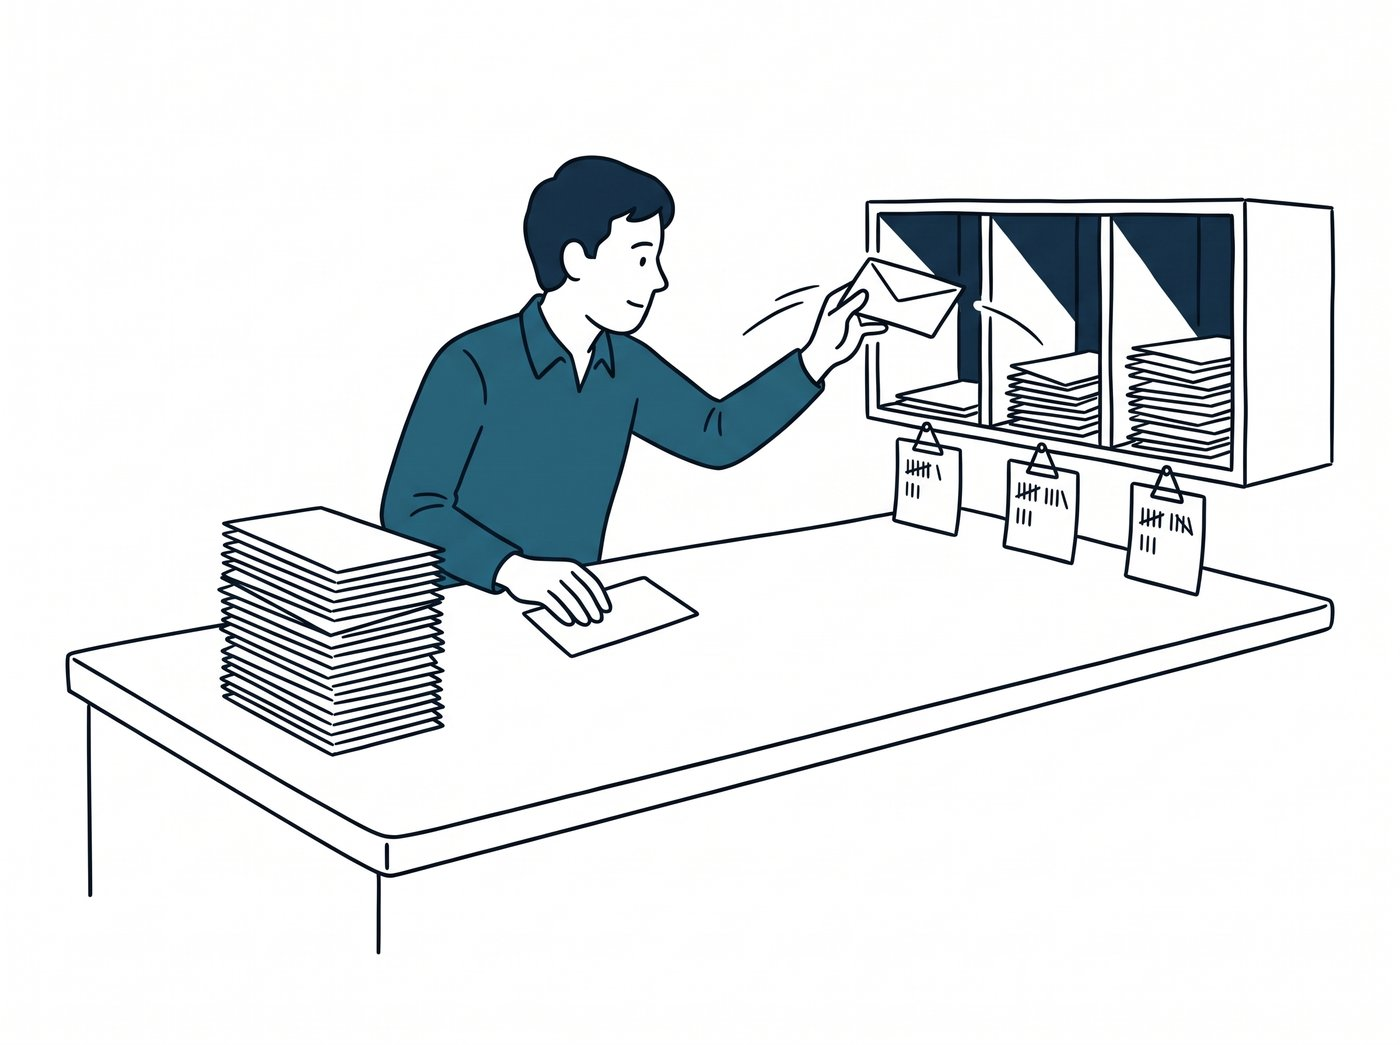<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">groupby ordnet jede Zeile dem Fach ihres Gruppenschlüssels zu; das ist kein Sortieren, die Zeilen werden nur verteilt. Erst die Zusammenfassung danach, hier das Zählen je Fach, liefert eine Zahl je Gruppe. Mit mean oder sum statt Zählen entsteht je Fach eine andere Kennzahl.</div></div>

In [ ]:
six = pd.DataFrame({"pclass": [1, 3, 2, 3, 1, 2], "survived": [1, 0, 1, 0, 0, 0]})
print(six.groupby("pclass")["survived"].mean())
s = pd.Series([1.0, 0.0, np.nan])
print("mean:", s.mean(), "| count:", s.count(), "| size:", s.size)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">six <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"pclass"</span>: [<span style="color: #666">1</span>, <span style="color: #666">3</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>, <span style="color: #666">1</span>, <span style="color: #666">2</span>], <span style="color: #BA2121">"survived"</span>: [<span style="color: #666">1</span>, <span style="color: #666">0</span>, <span style="color: #666">1</span>, <span style="color: #666">0</span>, <span style="color: #666">0</span>, <span style="color: #666">0</span>]})</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">groupby(&quot;pclass&quot;)</code> legt die Gruppen fest, <code style="color:inherit;">[&quot;survived&quot;]</code> wählt die Spalte, <code style="color:inherit;">mean()</code> fasst jede Gruppe zusammen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(six<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>)[<span style="color: #BA2121">"survived"</span>]<span style="color: #666">.</span>mean())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">mean</code> lässt fehlende Werte aus (Parameter <code style="color:inherit;">skipna</code>, Voreinstellung True): eine Lücke zählt weder oben noch unten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">s <span style="color: #666">=</span> pd<span style="color: #666">.</span>Series([<span style="color: #666">1.0</span>, <span style="color: #666">0.0</span>, np<span style="color: #666">.</span>nan])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"mean:"</span>, s<span style="color: #666">.</span>mean(), <span style="color: #BA2121">"| count:"</span>, s<span style="color: #666">.</span>count(), <span style="color: #BA2121">"| size:"</span>, s<span style="color: #666">.</span>size)</code></pre></details>

Das Ergebnis ist eine `Series`, deren Index die Gruppenschlüssel sind. Auf den Kursdaten dasselbe, dazu zwei Dinge, die bei fehlenden Werten wichtig sind: `mean` lässt Lücken aus, wie die kleine Series gezeigt hat, es teilt also durch die Anzahl der vorhandenen Werte. `size` zählt alle Zeilen einer Gruppe, `count` nur die vorhandenen Werte der gewählten Spalte.

In [ ]:
print(clean.groupby("pclass")["survived"].mean().round(3))
print()
print(pd.DataFrame({"size": clean.groupby("pclass")["age"].size(),
                    "count": clean.groupby("pclass")["age"].count(),
                    "mean": clean.groupby("pclass")["age"].mean().round(1)}))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>)[<span style="color: #BA2121">"survived"</span>]<span style="color: #666">.</span>mean()<span style="color: #666">.</span>round(<span style="color: #666">3</span>))
<span style="color: #008000">print</span>()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">size()</code> zählt Zeilen je Gruppe, <code style="color:inherit;">count()</code> zählt nur Werte, die nicht fehlen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"size"</span>: clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>)[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>size(),
                    <span style="color: #BA2121">"count"</span>: clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>)[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>count(),
                    <span style="color: #BA2121">"mean"</span>: clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>)[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>mean()<span style="color: #666">.</span>round(<span style="color: #666">1</span>)}))</code></pre></details>

Lücken gibt es auch im Gruppenschlüssel selbst. Zeilen, deren Schlüssel fehlt, lässt `groupby` standardmäßig weg. Sie landen in keiner Gruppe. `dropna=False` legt für sie eine eigene Gruppe an.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">clean.groupby("embarked").size().sum()</code> ergibt 1307, die Tabelle hat 1309 Zeilen. Wo sind die zwei Passagiere geblieben?</p>

</div>

In [ ]:
by_port = clean.groupby("embarked").size()
print(by_port.to_dict(), "Summe:", by_port.sum())
by_port_all = clean.groupby("embarked", dropna=False).size()
print(by_port_all.to_dict(), "Summe:", by_port_all.sum())

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; Zeilen mit fehlendem Gruppenschlüssel fallen bei <code style="color:inherit;">groupby</code> standardmäßig weg</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">by_port <span style="color: #666">=</span> clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"embarked"</span>)<span style="color: #666">.</span>size()
<span style="color: #008000">print</span>(by_port<span style="color: #666">.</span>to_dict(), <span style="color: #BA2121">"Summe:"</span>, by_port<span style="color: #666">.</span>sum())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">dropna=False</code> legt für die fehlenden Schlüssel eine eigene Gruppe an</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">by_port_all <span style="color: #666">=</span> clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"embarked"</span>, dropna<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)<span style="color: #666">.</span>size()
<span style="color: #008000">print</span>(by_port_all<span style="color: #666">.</span>to_dict(), <span style="color: #BA2121">"Summe:"</span>, by_port_all<span style="color: #666">.</span>sum())</code></pre></details>

Mit zwei Gruppenschlüsseln entsteht eine Series mit einem zweistufigen Index (ein MultiIndex), ein Eintrag je Kombination. `unstack` nimmt die innere Stufe und macht daraus Spalten, das Ergebnis ist eine Tabelle, wie man sie lesen möchte.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche Form hat <code style="color:inherit;">clean.groupby(["sex", "pclass"])["survived"].mean()</code>?</p>

</div>

In [ ]:
by_both = clean.groupby(["sex", "pclass"])["survived"].mean()
print(by_both.round(3))
print("Form:", by_both.shape)
print(by_both.unstack().round(3))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; eine Liste von Spalten gruppiert nach allen Kombinationen; das Ergebnis hat einen zweistufigen Index</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">by_both <span style="color: #666">=</span> clean<span style="color: #666">.</span>groupby([<span style="color: #BA2121">"sex"</span>, <span style="color: #BA2121">"pclass"</span>])[<span style="color: #BA2121">"survived"</span>]<span style="color: #666">.</span>mean()
<span style="color: #008000">print</span>(by_both<span style="color: #666">.</span>round(<span style="color: #666">3</span>))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Form:"</span>, by_both<span style="color: #666">.</span>shape)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">unstack()</code> macht aus der inneren Indexstufe (pclass) Spalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(by_both<span style="color: #666">.</span>unstack()<span style="color: #666">.</span>round(<span style="color: #666">3</span>))</code></pre></details>

Eine Schleife über die Zeilen (`for i, row in df.iterrows(): …`) würde dasselbe Ergebnis liefern, aber sie hat dasselbe Problem wie die Python-Schleife in LE03: Jeder Zugriff erzeugt ein Python-Objekt, und der Interpreter arbeitet jede Runde einzeln ab. `groupby` rechnet dagegen auf ganzen Arrays. Der Unterschied wächst mit der Zeilenzahl. In LE03 haben Sie ihn an der Schleife über die Zeilen eines Arrays gemessen.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: agg, pivot_table und crosstab</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">agg</code> fasst mit mehreren Kennzahlen auf einmal zusammen, <code style="color:inherit;">pivot_table</code> ist <code style="color:inherit;">groupby</code> mit <code style="color:inherit;">unstack</code> in einem Aufruf, und <code style="color:inherit;">crosstab</code> zählt Häufigkeiten zweier Spalten gegeneinander: <code style="color:inherit;">pd.crosstab(small["sex"], small["pclass"])</code> ergibt eine Tabelle mit <code style="color:inherit;">female</code> und <code style="color:inherit;">male</code> in den Zeilen, den Klassen 1, 2, 3 in den Spalten und den Zählwerten 1, 0, 1 und 1, 1, 1.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p><code style="color:inherit;">clean.groupby("pclass")["age"].agg(["mean", "median", "count"])</code> liefert drei Spalten. <code style="color:inherit;">clean.pivot_table(values="survived", index="sex", columns="pclass", aggfunc="mean")</code> ist die Tabelle aus der Zelle oben. <code style="color:inherit;">pd.crosstab(clean["sex"], clean["pclass"])</code> zählt, wie viele Frauen und Männer je Klasse. Es liefert Häufigkeiten (Anzahlen), keine Raten (Anteile wie die Überlebensrate). Für Raten braucht <code style="color:inherit;">crosstab</code> zusätzlich <code style="color:inherit;">values=clean["survived"], aggfunc="mean"</code>. Im Termin genügen <code style="color:inherit;">groupby</code>, <code style="color:inherit;">mean</code>, <code style="color:inherit;">size</code> und <code style="color:inherit;">unstack</code>; <code style="color:inherit;">crosstab</code> und <code style="color:inherit;">agg</code> kommen in der Projektaufgabe vor.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.5 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Vier <code style="color:inherit;">groupby</code>-Zeilen auf <code style="color:inherit;">small</code>. Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, ausführen, vergleichen. Achten Sie auf die Lücke im Alter.</p>

</div>
</div>

In [ ]:
print(small.groupby("pclass").size().to_dict())                        # -> ?
print(small.groupby("sex")["age"].mean().round(2).to_dict())           # -> ?
print(small.groupby("pclass")["age"].count().to_dict())                # -> ?
print(small.groupby(["pclass", "sex"]).size().unstack(fill_value=0))   # -> ?

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 4.5 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Eine Gruppe, eine Kennzahl. Ersetzen Sie jedes <code style="color:inherit;">...</code> durch einen Ausdruck auf der bereinigten Tabelle <code style="color:inherit;">clean</code>, jeweils ein <code style="color:inherit;">groupby</code> mit einer Zusammenfassung:</p>
<ul>
<li>a) Wie viele Passagiere reisen in jeder Klasse? Eine Series mit der Klasse im Index.</li>
<li>b) Wie alt sind Frauen und Männer im Durchschnitt? Eine Series mit dem Geschlecht im Index.</li>
<li>c) Wie hoch ist die Überlebensrate je Einstiegshafen? Eine Series mit dem Hafen im Index.</li>
</ul>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> a) <code style="color:inherit;">size()</code> direkt auf dem <code style="color:inherit;">groupby</code>, b) und c) erst die Spalte wählen (<code style="color:inherit;">["age"]</code>, <code style="color:inherit;">["survived"]</code>), dann <code style="color:inherit;">mean()</code>; der Mittelwert einer 0/1-Spalte ist der Anteil der Einsen.</p></div></details>
</div>
</div>

In [ ]:
a = ...   # a) Passagiere je Klasse
b = ...   # b) Durchschnittsalter je Geschlecht
c = ...   # c) Überlebensrate je Hafen

In [ ]:
# Prüfzelle — einfach ausführen
assert isinstance(a, pd.Series) and a.to_dict() == {1: 323, 2: 277, 3: 709}, "a) 323, 277 und 709 Passagiere, Index = Klasse"
assert isinstance(b, pd.Series) and b.round(2).to_dict() == {"female": 28.69, "male": 30.53}, f"b) Frauen im Mittel 28.69 Jahre, Männer 30.53, nicht {b.round(2).to_dict()}"
assert isinstance(c, pd.Series) and c.round(3).to_dict() == {"C": 0.556, "Q": 0.358, "S": 0.333}, f"c) Cherbourg 55.6 %, Queenstown 35.8 %, Southampton 33.3 %, nicht {c.round(3).to_dict()}"
print("je Klasse:", a.to_dict(), "| Alter:", b.round(1).to_dict(), "| Rate:", c.round(3).to_dict())
print("Alle Prüfungen bestanden ✓")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 4.5 #3</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">survival_table(df)</code>. Sie gibt die Überlebensrate nach Geschlecht und Klasse als Tabelle zurück, mit den Geschlechtern als Zeilen und den Klassen 1, 2, 3 als Spalten. Die Prüfzelle prüft Form und Werte.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">groupby</code> mit zwei Schlüsseln, dann <code style="color:inherit;">unstack</code> auf das Ergebnis.</p></div></details>
</div>
</div>

In [ ]:
def survival_table(df):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
table = survival_table(clean)
assert table is not None, "survival_table gibt noch nichts zurück (return vergessen?)"
assert table.shape == (2, 3), f"zwei Zeilen (Geschlecht) und drei Spalten (Klasse) erwartet, nicht {table.shape}"
assert list(table.index) == ["female", "male"] and list(table.columns) == [1, 2, 3], "Zeilen female/male, Spalten 1, 2, 3"
for sx in table.index:                                            # alle sechs Werte gegen eine Masken-Referenz
    for pc in table.columns:
        mask = (clean["sex"] == sx) & (clean["pclass"] == pc)
        assert abs(table.loc[sx, pc] - clean.loc[mask, "survived"].mean()) < 1e-9, f"{sx}, Klasse {pc}: Überlebensrate stimmt nicht"
assert abs(table.loc["female", 1] - 0.965) < 0.001, "Frauen in der ersten Klasse: rund 96,5 %"
print(table.round(3))
print("Alle Prüfungen bestanden ✓")

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Gruppieren und Zusammenfassen</span></div>
<p><code style="color:inherit;">groupby</code> legt die Gruppen fest, erst <code style="color:inherit;">mean</code>, <code style="color:inherit;">sum</code>, <code style="color:inherit;">size</code> oder <code style="color:inherit;">count</code> fasst jede Gruppe zu einer Zahl zusammen. Bei einer ausgewählten Spalte entsteht eine Series mit den Gruppenschlüsseln als Index; ohne Spaltenauswahl ein DataFrame. Ergebnisse an <code style="color:inherit;">small</code>.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>Mittelwert je Gruppe</td>
<td><code style="color:inherit;">small.groupby("sex")["age"].mean()</code></td>
<td><code style="color:inherit;">female 23.5, male 27.375</code>, Lücke ausgelassen</td>
</tr>
<tr>
<td>Zeilen je Gruppe</td>
<td><code style="color:inherit;">small.groupby("pclass").size()</code></td>
<td><code style="color:inherit;">1: 2, 2: 1, 3: 2</code></td>
</tr>
<tr>
<td>vorhandene Werte je Gruppe</td>
<td><code style="color:inherit;">small.groupby("pclass")["age"].count()</code></td>
<td><code style="color:inherit;">1: 2, 2: 1, 3: 1</code></td>
</tr>
<tr>
<td>zwei Schlüssel</td>
<td><code style="color:inherit;">je = small.groupby(["pclass", "sex"]).size()</code></td>
<td>Series mit zweistufigem Index</td>
</tr>
<tr>
<td>als Tabelle</td>
<td><code style="color:inherit;">je.unstack(fill_value=0)</code></td>
<td>Zeilen <code style="color:inherit;">pclass</code>, Spalten <code style="color:inherit;">sex</code></td>
</tr>
<tr>
<td>Häufigkeiten gegeneinander</td>
<td><code style="color:inherit;">pd.crosstab(small["sex"], small["pclass"])</code></td>
<td>Tabelle 2 × 3</td>
</tr>
<tr>
<td>Häufigkeit je Wert</td>
<td><code style="color:inherit;">small["sex"].value_counts()</code></td>
<td><code style="color:inherit;">male 3, female 2</code>, absteigend</td>
</tr>
<tr>
<td>Kennzahlen einer Zahlenspalte</td>
<td><code style="color:inherit;">small["age"].describe()</code></td>
<td>Anzahl, Mittelwert, Streuung, Quantile</td>
</tr>
</tbody>
</table>
<p><strong>Falle:</strong> Zeilen mit fehlendem Gruppenschlüssel lässt <code style="color:inherit;">groupby</code> weg; <code style="color:inherit;">dropna=False</code> legt für sie eine eigene Gruppe an. Der Mittelwert einer 0/1-Spalte ist der Anteil der Einsen, also eine Rate.</p>

</div>

## <a id="kap-darstellen-mit-matplotlib"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.6&nbsp;&nbsp;Darstellen mit Matplotlib</span>

Die Überlebensraten aus dem letzten Kapitel lassen sich als Diagramm schneller vergleichen als in der Tabelle. Matplotlib ist die Bibliothek hierfür; bei der Kosinus-Kurve in LE01 hatten wir sie schon einmal verwendet. Das Modell dahinter hat zwei Teile: Die `Figure` ist das Blatt, die `Axes` sind ein Koordinatensystem darauf. `plt.subplots()` liefert beide. Gezeichnet und beschriftet wird mit Methoden des Koordinatensystems `ax`, etwa `ax.bar` oder `ax.set_title`; das Blatt `fig` braucht man zum Speichern und für die Anordnung mehrerer Koordinatensysteme. Diese Form ist im Kurs die einzige, die wir benötigen. Sie funktioniert auch mit mehreren Koordinatensystemen auf einem Blatt.

Ein Balkendiagramm für die Überlebensrate je Klasse: Die Werte kommen aus `groupby`, die Kategorien aus dem Index des Ergebnisses. Jede Achse bekommt eine Beschriftung, das Diagramm einen Titel. Das ist die Mindestausstattung, die Legende kommt beim Streudiagramm dazu.

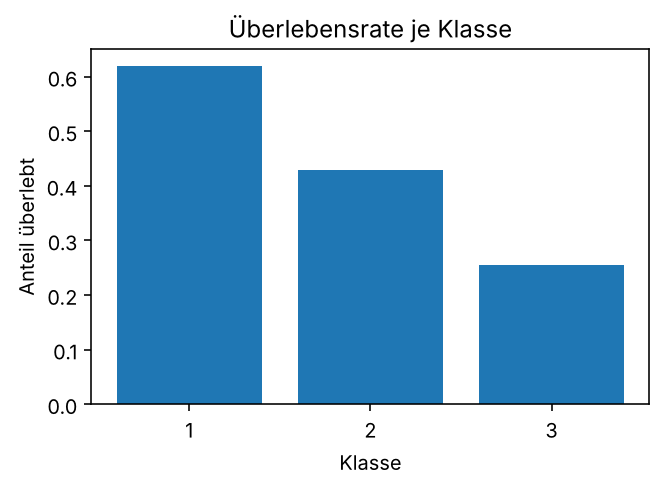

In [ ]:
rates = clean.groupby("pclass")["survived"].mean()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(rates.index.astype(str), rates.to_numpy())
ax.set_xlabel("Klasse")
ax.set_ylabel("Anteil überlebt")
ax.set_title("Überlebensrate je Klasse")
plt.show()

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">rates <span style="color: #666">=</span> clean<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>)[<span style="color: #BA2121">"survived"</span>]<span style="color: #666">.</span>mean()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">plt.subplots()</code> liefert das Blatt <code style="color:inherit;">fig</code> und ein Koordinatensystem <code style="color:inherit;">ax</code>; <code style="color:inherit;">figsize</code> ist die Größe in Zoll</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">fig, ax <span style="color: #666">=</span> plt<span style="color: #666">.</span>subplots(figsize<span style="color: #666">=</span>(<span style="color: #666">5</span>, <span style="color: #666">3.2</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">ax.bar(x, höhen)</code> zeichnet je Eintrag einen Balken: <code style="color:inherit;">x</code> sind die Klassen aus dem Index von <code style="color:inherit;">rates</code>, als Text, damit sie Kategorien bleiben; die Höhen sind die drei Überlebensraten aus <code style="color:inherit;">rates</code>, als Array</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ax<span style="color: #666">.</span>bar(rates<span style="color: #666">.</span>index<span style="color: #666">.</span>astype(<span style="color: #008000">str</span>), rates<span style="color: #666">.</span>to_numpy())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; die drei Beschriftungen, jede eine Methode am <code style="color:inherit;">ax</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ax<span style="color: #666">.</span>set_xlabel(<span style="color: #BA2121">"Klasse"</span>)
ax<span style="color: #666">.</span>set_ylabel(<span style="color: #BA2121">"Anteil überlebt"</span>)
ax<span style="color: #666">.</span>set_title(<span style="color: #BA2121">"Überlebensrate je Klasse"</span>)
plt<span style="color: #666">.</span>show()</code></pre></details>

Ein Histogramm zeigt die Verteilung einer Zahlenspalte: Es teilt den Wertebereich in Intervalle und zählt je Intervall. Die Intervallgrenzen geben wir fest vor (`bins=range(0, 90, 10)`, also 0 bis 10, 10 bis 20 und so weiter bis 80), damit das Diagramm reproduzierbar ist. Fehlende Werte kann ein Histogramm nicht einsortieren. `dropna()` entfernt sie vorher, und die Anzahl der gezeichneten Werte gehört in den Titel, damit niemand 1309 Passagiere vermutet. Die Gesamttabelle bleibt dabei unverändert.

je Intervall: [82, 143, 343, 232, 135, 70, 32, 7]


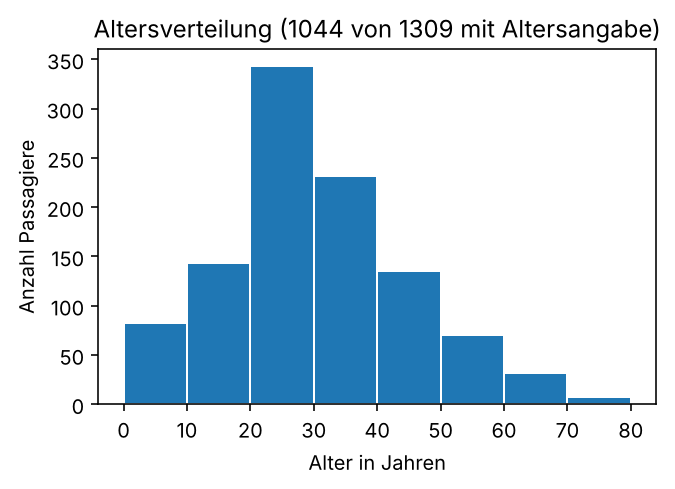

In [ ]:
AGE_BINS = range(0, 90, 10)
ages = clean["age"].dropna()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(ages, bins=AGE_BINS, edgecolor="white")
ax.set_xlabel("Alter in Jahren")
ax.set_ylabel("Anzahl Passagiere")
ax.set_title(f"Altersverteilung ({len(ages)} von {len(clean)} mit Altersangabe)")
plt.show()
print("je Intervall:", np.histogram(ages, bins=AGE_BINS)[0].tolist())

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">AGE_BINS <span style="color: #666">=</span> <span style="color: #008000">range</span>(<span style="color: #666">0</span>, <span style="color: #666">90</span>, <span style="color: #666">10</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">dropna()</code> liefert die Series ohne fehlende Werte; <code style="color:inherit;">clean</code> selbst bleibt, wie sie ist</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ages <span style="color: #666">=</span> clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>dropna()
fig, ax <span style="color: #666">=</span> plt<span style="color: #666">.</span>subplots(figsize<span style="color: #666">=</span>(<span style="color: #666">5</span>, <span style="color: #666">3.2</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">ax.hist(werte, bins=grenzen)</code> zählt je Intervall und zeichnet die Balken; <code style="color:inherit;">edgecolor</code> macht die Grenzen sichtbar</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ax<span style="color: #666">.</span>hist(ages, bins<span style="color: #666">=</span>AGE_BINS, edgecolor<span style="color: #666">=</span><span style="color: #BA2121">"white"</span>)
ax<span style="color: #666">.</span>set_xlabel(<span style="color: #BA2121">"Alter in Jahren"</span>)
ax<span style="color: #666">.</span>set_ylabel(<span style="color: #BA2121">"Anzahl Passagiere"</span>)
ax<span style="color: #666">.</span>set_title(<span style="color: #BA2121">f"Altersverteilung (</span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(ages)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> von </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(clean)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> mit Altersangabe)"</span>)
plt<span style="color: #666">.</span>show()
<span style="color: #008000">print</span>(<span style="color: #BA2121">"je Intervall:"</span>, np<span style="color: #666">.</span>histogram(ages, bins<span style="color: #666">=</span>AGE_BINS)[<span style="color: #666">0</span>]<span style="color: #666">.</span>tolist())</code></pre></details>

Ein Streudiagramm zeigt zwei Zahlenspalten gegeneinander, ein Punkt je Zeile: hier das Alter auf der x-Achse und der Fahrpreis auf der y-Achse. Dafür braucht jede Zeile beide Werte, und `dropna(subset=["age", "fare"])` behält nur die vollständigen Paare, 1043 von 1309.

Die Farbe nach Klasse entsteht in drei Schritten. Eine Schleife über `df.groupby("pclass")` liefert je Klasse den Schlüssel und die Teiltabelle; das ist der erste Schritt aus der Grafik Split-apply-combine, ohne das Zusammenfassen. Für jede Teiltabelle folgt ein eigener `scatter`-Aufruf. Das Argument `label` gibt jedem Aufruf seinen Eintrag in der Legende.

Der Fahrpreis ist schief verteilt: Die meisten Werte liegen unter 50 Pfund, wenige über 500. Auf einer gewöhnlichen Achse drängen sich die vielen kleinen Werte am unteren Rand. Eine logarithmische y-Achse (`ax.set_yscale("log")`) zieht sie auseinander: Gleiche Abstände bedeuten dort gleiche Faktoren, von 10 auf 100 ist so weit wie von 100 auf 1000. Der Preis dafür: Den Logarithmus von 0 gibt es nicht, und acht der 1043 Passagiere haben den Fahrpreis 0. Diese acht Punkte fehlen im Diagramm, deshalb nennt der Titel beide Zahlen.

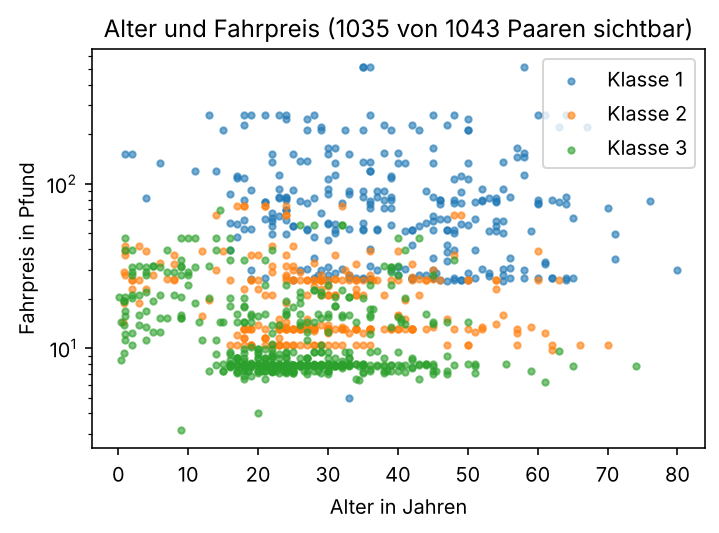

In [ ]:
pairs = clean.dropna(subset=["age", "fare"])
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for pclass, group in pairs.groupby("pclass"):
    ax.scatter(group["age"], group["fare"], s=10, alpha=0.6, label=f"Klasse {pclass}")
ax.set_xlabel("Alter in Jahren")
ax.set_ylabel("Fahrpreis in Pfund")
ax.set_title(f"Alter und Fahrpreis ({(pairs['fare'] > 0).sum()} von {len(pairs)} Paaren sichtbar)")
ax.set_yscale("log")
ax.legend()
plt.show()

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">dropna(subset=[...])</code> entfernt nur Zeilen, in denen eine der genannten Spalten fehlt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">pairs <span style="color: #666">=</span> clean<span style="color: #666">.</span>dropna(subset<span style="color: #666">=</span>[<span style="color: #BA2121">"age"</span>, <span style="color: #BA2121">"fare"</span>])
fig, ax <span style="color: #666">=</span> plt<span style="color: #666">.</span>subplots(figsize<span style="color: #666">=</span>(<span style="color: #666">5.5</span>, <span style="color: #666">3.6</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; die Schleife über <code style="color:inherit;">groupby</code> liefert je Gruppe den Schlüssel (<code style="color:inherit;">pclass</code>) und die Teiltabelle (<code style="color:inherit;">group</code>)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">for</span> pclass, group <span style="color: #A2F; font-weight: bold">in</span> pairs<span style="color: #666">.</span>groupby(<span style="color: #BA2121">"pclass"</span>):</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; ein <code style="color:inherit;">scatter</code> je Gruppe: <code style="color:inherit;">label</code> ist der Text in der Legende, <code style="color:inherit;">s</code> die Punktgröße, <code style="color:inherit;">alpha</code> die Deckkraft</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">    ax<span style="color: #666">.</span>scatter(group[<span style="color: #BA2121">"age"</span>], group[<span style="color: #BA2121">"fare"</span>], s<span style="color: #666">=10</span>, alpha<span style="color: #666">=0.6</span>, label<span style="color: #666">=</span><span style="color: #BA2121">f"Klasse </span><span style="color: #A45A77; font-weight: bold">{</span>pclass<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>)
ax<span style="color: #666">.</span>set_xlabel(<span style="color: #BA2121">"Alter in Jahren"</span>)
ax<span style="color: #666">.</span>set_ylabel(<span style="color: #BA2121">"Fahrpreis in Pfund"</span>)
ax<span style="color: #666">.</span>set_title(<span style="color: #BA2121">f"Alter und Fahrpreis (</span><span style="color: #A45A77; font-weight: bold">{</span>(pairs[<span style="color: #BA2121">'fare'</span>]<span style="color: #BBB"> </span><span style="color: #666">&gt;</span><span style="color: #BBB"> </span><span style="color: #666">0</span>)<span style="color: #666">.</span>sum()<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> von </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(pairs)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> Paaren sichtbar)"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">set_yscale(&quot;log&quot;)</code> stellt die y-Achse logarithmisch dar; Fahrpreis 0 fällt dabei weg (log(0) gibt es nicht)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ax<span style="color: #666">.</span>set_yscale(<span style="color: #BA2121">"log"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>⑤</b>&nbsp; <code style="color:inherit;">legend()</code> zeigt die Einträge aus den <code style="color:inherit;">label</code>-Angaben</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ax<span style="color: #666">.</span>legend()
plt<span style="color: #666">.</span>show()</code></pre></details>

Mehrere Koordinatensysteme auf einem Blatt liefert `plt.subplots(1, 3)`: ein Blatt, drei `Axes` nebeneinander, als Array aus drei `Axes`, das sich wie ein Tupel auspacken lässt. `df.plot(kind=..., ax=ax)` ist eine Abkürzung von pandas, die in ein gegebenes `ax` zeichnet. Sie liefert dasselbe `ax` zurück, Beschriftungen setzen Sie wie bisher. Die nächste Zelle zeigt beides und ist zugleich das Gerüst für die Aufgabe.

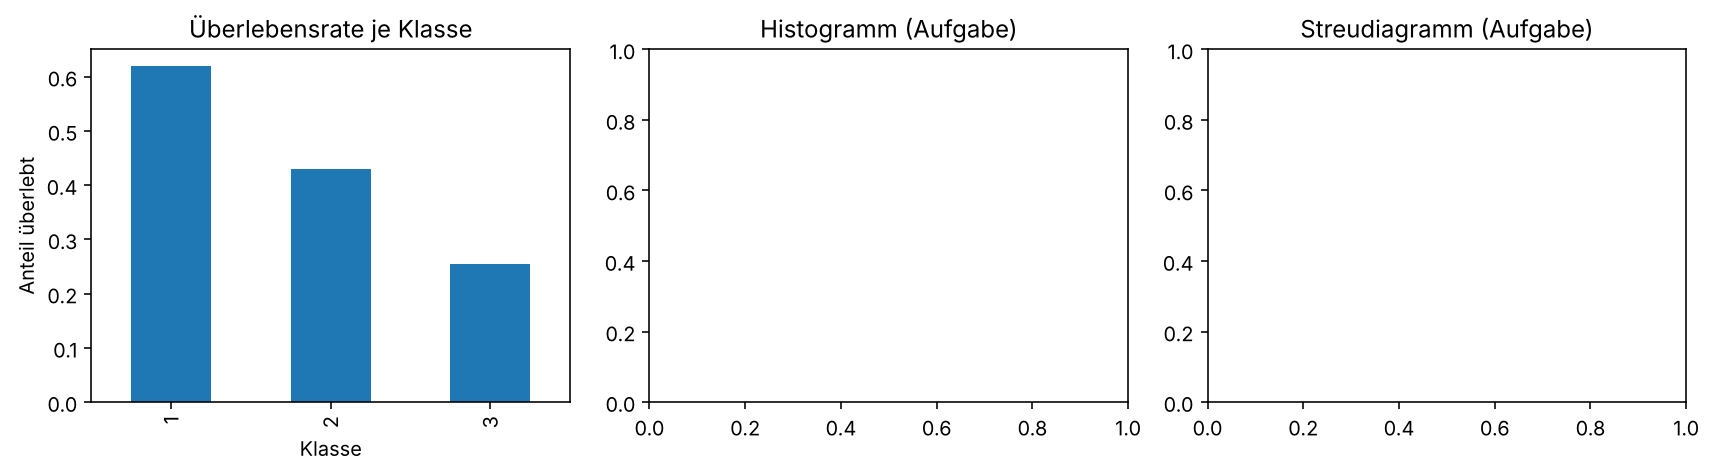

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.4))
rates.plot(kind="bar", ax=ax1)
ax1.set_xlabel("Klasse")
ax1.set_ylabel("Anteil überlebt")
ax1.set_title("Überlebensrate je Klasse")
ax2.set_title("Histogramm (Aufgabe)")
ax3.set_title("Streudiagramm (Aufgabe)")
fig.tight_layout()
plt.show()

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">subplots(1, 3)</code> liefert ein Blatt und ein Array aus drei Koordinatensystemen, hier in drei Namen ausgepackt; <code style="color:inherit;">figsize</code> gilt für das ganze Blatt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">fig, (ax1, ax2, ax3) <span style="color: #666">=</span> plt<span style="color: #666">.</span>subplots(<span style="color: #666">1</span>, <span style="color: #666">3</span>, figsize<span style="color: #666">=</span>(<span style="color: #666">12</span>, <span style="color: #666">3.4</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">series.plot(kind=&quot;bar&quot;, ax=ax1)</code> zeichnet die Series als Balken in <code style="color:inherit;">ax1</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">rates<span style="color: #666">.</span>plot(kind<span style="color: #666">=</span><span style="color: #BA2121">"bar"</span>, ax<span style="color: #666">=</span>ax1)
ax1<span style="color: #666">.</span>set_xlabel(<span style="color: #BA2121">"Klasse"</span>)
ax1<span style="color: #666">.</span>set_ylabel(<span style="color: #BA2121">"Anteil überlebt"</span>)
ax1<span style="color: #666">.</span>set_title(<span style="color: #BA2121">"Überlebensrate je Klasse"</span>)
ax2<span style="color: #666">.</span>set_title(<span style="color: #BA2121">"Histogramm (Aufgabe)"</span>)
ax3<span style="color: #666">.</span>set_title(<span style="color: #BA2121">"Streudiagramm (Aufgabe)"</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">tight_layout()</code> rückt die Koordinatensysteme so, dass Beschriftungen nicht überlappen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">fig<span style="color: #666">.</span>tight_layout()
plt<span style="color: #666">.</span>show()</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Diagramme speichern</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">fig.savefig("analyse.png", dpi=150)</code> schreibt das Blatt als Bilddatei. <code style="color:inherit;">dpi</code> ist die Auflösung in Punkten je Zoll, 150 reicht für Dokumente, 300 für den Druck.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Das Format folgt der Dateiendung: <code style="color:inherit;">.png</code> für Rasterbilder aus Bildpunkten (Pixeln), <code style="color:inherit;">.svg</code> oder <code style="color:inherit;">.pdf</code> für Vektorgrafiken, die sich verlustfrei skalieren lassen. <code style="color:inherit;">bbox_inches="tight"</code> schneidet überflüssigen Rand ab. In Notebooks zeigt <code style="color:inherit;">plt.show()</code> das Blatt an. Wenn Sie beides wollen, rufen Sie <code style="color:inherit;">savefig</code> am einfachsten vor <code style="color:inherit;">show</code> auf. Mit der Referenz <code style="color:inherit;">fig</code> funktioniert <code style="color:inherit;">fig.savefig</code> auch danach. Eine bekannte Fehlerquelle ist <code style="color:inherit;">plt.savefig()</code> nach einem blockierenden <code style="color:inherit;">plt.show()</code> in einem Skript außerhalb des Notebooks, dort ist das aktuelle Blatt dann schon geschlossen.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">10 min</span>✏️ Aufgabe 4.6 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die Aufgabe hat zwei Teile: Zuerst schreiben Sie zwei Datenfunktionen, die eine eigene Prüfzelle testet, danach zeichnen Sie.</p>
<ol>
<li>Schreiben Sie <code style="color:inherit;">valid_ages(df)</code>, das die Alterswerte ohne Lücken als Series zurückgibt, und <code style="color:inherit;">age_fare_pairs(df)</code>, das die Zeilen mit Alter und Fahrpreis als DataFrame mit genau den Spalten <code style="color:inherit;">age</code>, <code style="color:inherit;">fare</code> und <code style="color:inherit;">pclass</code> zurückgibt. Die Prüfzelle prüft Anzahl und Werte.</li>
<li>Zeichnen Sie in der Zelle danach in das vorgegebene Gerüst: in <code style="color:inherit;">ax2</code> das Histogramm von <code style="color:inherit;">valid_ages(clean)</code> mit den Intervallgrenzen <code style="color:inherit;">AGE_BINS</code>, in <code style="color:inherit;">ax3</code> das Streudiagramm Alter gegen Fahrpreis aus <code style="color:inherit;">age_fare_pairs(clean)</code>, ein <code style="color:inherit;">scatter</code> je Klasse mit <code style="color:inherit;">label</code>, logarithmischer y-Achse und Legende. Beide mit Achsenbeschriftung und, wie in den Demo-Zellen, mit der Anzahl der dargestellten Werte im Titel; bei drei Diagrammen nebeneinander passt die Anzahl in eine zweite Titelzeile (<code style="color:inherit;">\n</code> im Titeltext). Die Prüfzelle prüft die Intervalle und Balkenhöhen, die Punkte je Klasse und die Beschriftung.</li>
</ol>
<p>Wer früher fertig ist: Schreiben Sie in einer neuen Zelle <code style="color:inherit;">age_by_sex(df)</code>, das ein Dict mit den Alterswerten je Geschlecht liefert (<code style="color:inherit;">{"female": Series, "male": Series}</code>), und zeichnen Sie beide als Histogramme in ein gemeinsames <code style="color:inherit;">ax</code> mit <code style="color:inherit;">alpha=0.5</code> und <code style="color:inherit;">label</code>, damit sich die Verteilungen überlagern.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Beide Datenfunktionen stehen fast wörtlich in den Zellen oben (<code style="color:inherit;">dropna()</code> und <code style="color:inherit;">dropna(subset=[...])</code>), nur die Spaltenauswahl <code style="color:inherit;">[["age", "fare", "pclass"]]</code> kommt dazu. Für das Zeichnen übernehmen Sie die Zeilen aus den Demo-Zellen und ersetzen <code style="color:inherit;">ax</code> durch <code style="color:inherit;">ax2</code> beziehungsweise <code style="color:inherit;">ax3</code>.</p></div></details>
</div>
</div>

In [ ]:
def valid_ages(df):
    # TODO: Ihre Lösung hier
    ...

def age_fare_pairs(df):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
ages = valid_ages(clean)
pairs = age_fare_pairs(clean)
assert ages is not None and pairs is not None, "eine der beiden Funktionen gibt noch nichts zurück"
assert len(ages) == 1044 and ages.isna().sum() == 0, f"1044 Alterswerte ohne Lücken erwartet, nicht {len(ages)}"
# Vergleichswerte unabhängig über Masken gebildet; die Reihenfolge ist frei, verglichen wird sortiert
ref_ages = clean.loc[clean["age"].notna(), "age"].to_numpy()
assert np.array_equal(np.sort(ages.to_numpy()), np.sort(ref_ages)), "valid_ages soll genau die vorhandenen Alterswerte liefern, jeden einmal"
assert list(pairs.columns) == ["age", "fare", "pclass"], "age_fare_pairs: genau die Spalten age, fare, pclass"
assert len(pairs) == 1043 and pairs.isna().sum().sum() == 0, f"1043 vollständige Paare erwartet, nicht {len(pairs)}"
ref_pairs = clean.loc[clean["age"].notna() & clean["fare"].notna(), ["age", "fare", "pclass"]]
assert np.array_equal(pairs.sort_values(["age", "fare", "pclass"]).to_numpy(),
                      ref_pairs.sort_values(["age", "fare", "pclass"]).to_numpy()), "age_fare_pairs: die Werte einer Zeile müssen zusammenbleiben (zeilenweise auswählen, nicht spaltenweise)"
print("Alle Prüfungen bestanden ✓")

In [ ]:
# Gerüst: das Blatt mit drei Koordinatensystemen, ax1 ist fertig, ax2 und ax3 sind Ihre Aufgabe
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.4))
rates.plot(kind="bar", ax=ax1)
ax1.set_xlabel("Klasse")
ax1.set_ylabel("Anteil überlebt")
ax1.set_title("Überlebensrate je Klasse")
# TODO: Ihre Lösung hier
...
fig.tight_layout()
plt.show()

In [ ]:
# Prüfzelle — einfach ausführen
# Vergleichswerte unabhängig über Masken, wie in der Prüfzelle davor
ref_ages = clean.loc[clean["age"].notna(), "age"].to_numpy()
ref_pairs = clean.loc[clean["age"].notna() & clean["fare"].notna(), ["age", "fare", "pclass"]]
# Histogramm: ein Balken je Intervall, Lage und Breite aus AGE_BINS, Höhen = Anzahl je Intervall
assert len(ax2.patches) == 8, f"acht Balken für die Intervalle 0 bis 80 erwartet, nicht {len(ax2.patches)}"
assert [round(p.get_x()) for p in ax2.patches] == list(AGE_BINS)[:-1], "die Balken sollen bei 0, 10, …, 70 beginnen (bins=AGE_BINS)"
assert all(round(p.get_width()) == 10 for p in ax2.patches), "jeder Balken soll zehn Jahre breit sein"
heights = [p.get_height() for p in ax2.patches]
expected = np.histogram(ref_ages, bins=AGE_BINS)[0].tolist()
assert heights == expected, f"Balkenhöhen {heights} passen nicht zu den Häufigkeiten {expected}"
assert ax2.get_xlabel() and ax2.get_ylabel(), "ax2: beide Achsen beschriften"
assert str(len(ref_ages)) in ax2.get_title(), f"ax2: Titel mit der Anzahl der dargestellten Werte ({len(ref_ages)})"
# Streudiagramm: je Legendeneintrag die Punkte der passenden Klasse, Mehrfachpunkte mitgezählt
assert len(ax3.collections) == 3, f"ein scatter je Klasse, also drei, nicht {len(ax3.collections)}"
assert ax3.get_legend() is not None, "ax3: Legende fehlt"
handles, labels = ax3.get_legend_handles_labels()
assert len(set(labels)) == 3 and all(any(ch in lab for ch in "123") for lab in labels), "ax3: drei Legendeneinträge mit der Klassennummer, zum Beispiel 'Klasse 1'"
def sorted_rows(a):                                  # Zeilen eines (N, 2)-Arrays lexikografisch ordnen, für den Vergleich zweier Punktmengen
    a = np.asarray(a, dtype=float).round(4)
    return a[np.lexsort((a[:, 1], a[:, 0]))]
total = 0
for handle, lab in zip(handles, labels):
    pclass = int(next(ch for ch in lab if ch in "123"))
    drawn = np.asarray(handle.get_offsets(), dtype=float)
    drawn = drawn[np.isfinite(drawn).all(axis=1)]
    wanted = ref_pairs.loc[ref_pairs["pclass"] == pclass, ["age", "fare"]].to_numpy()
    assert len(drawn) == len(wanted), f"'{lab}': {len(wanted)} Punkte erwartet, gezeichnet {len(drawn)}; stimmt die Zuordnung von Gruppe und label?"
    assert np.array_equal(sorted_rows(drawn), sorted_rows(wanted)), f"'{lab}': die Punkte sollen (Alter, Fahrpreis) der Klasse {pclass} sein; sind die Achsen vertauscht oder die Klassen verwechselt?"
    total += len(drawn)
assert total == 1043, f"1043 Punkte erwartet, nicht {total}"
assert len({tuple(c.get_facecolor()[0]) for c in ax3.collections}) == 3, "ax3: drei verschiedene Farben, eine je Klasse"
assert ax3.get_yscale() == "log", "ax3: y-Achse logarithmisch"
assert ax3.get_xlabel() and ax3.get_ylabel(), "ax3: beide Achsen beschriften"
assert str(int((ref_pairs["fare"] > 0).sum())) in ax3.get_title(), f"ax3: Titel mit der Anzahl der sichtbaren Punkte ({int((ref_pairs['fare'] > 0).sum())})"
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
<span style="color: #3D7B7B; font-style: italic"># Vergleichswerte unabhängig über Masken, wie in der Prüfzelle davor</span>
ref_ages <span style="color: #666">=</span> clean<span style="color: #666">.</span>loc[clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>notna(), <span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>to_numpy()
ref_pairs <span style="color: #666">=</span> clean<span style="color: #666">.</span>loc[clean[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>notna() <span style="color: #666">&amp;</span> clean[<span style="color: #BA2121">"fare"</span>]<span style="color: #666">.</span>notna(), [<span style="color: #BA2121">"age"</span>, <span style="color: #BA2121">"fare"</span>, <span style="color: #BA2121">"pclass"</span>]]
<span style="color: #3D7B7B; font-style: italic"># Histogramm: ein Balken je Intervall, Lage und Breite aus AGE_BINS, Höhen = Anzahl je Intervall</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">ax.patches</code> sind die gezeichneten Rechtecke; <code style="color:inherit;">get_x()</code>, <code style="color:inherit;">get_width()</code> und <code style="color:inherit;">get_height()</code> ihre Lage und Größe</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(ax2<span style="color: #666">.</span>patches) <span style="color: #666">==</span> <span style="color: #666">8</span>, <span style="color: #BA2121">f"acht Balken für die Intervalle 0 bis 80 erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(ax2<span style="color: #666">.</span>patches)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> [<span style="color: #008000">round</span>(p<span style="color: #666">.</span>get_x()) <span style="color: #008000; font-weight: bold">for</span> p <span style="color: #A2F; font-weight: bold">in</span> ax2<span style="color: #666">.</span>patches] <span style="color: #666">==</span> <span style="color: #008000">list</span>(AGE_BINS)[:<span style="color: #666">-1</span>], <span style="color: #BA2121">"die Balken sollen bei 0, 10, …, 70 beginnen (bins=AGE_BINS)"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">all</span>(<span style="color: #008000">round</span>(p<span style="color: #666">.</span>get_width()) <span style="color: #666">==</span> <span style="color: #666">10</span> <span style="color: #008000; font-weight: bold">for</span> p <span style="color: #A2F; font-weight: bold">in</span> ax2<span style="color: #666">.</span>patches), <span style="color: #BA2121">"jeder Balken soll zehn Jahre breit sein"</span>
heights <span style="color: #666">=</span> [p<span style="color: #666">.</span>get_height() <span style="color: #008000; font-weight: bold">for</span> p <span style="color: #A2F; font-weight: bold">in</span> ax2<span style="color: #666">.</span>patches]
expected <span style="color: #666">=</span> np<span style="color: #666">.</span>histogram(ref_ages, bins<span style="color: #666">=</span>AGE_BINS)[<span style="color: #666">0</span>]<span style="color: #666">.</span>tolist()
<span style="color: #008000; font-weight: bold">assert</span> heights <span style="color: #666">==</span> expected, <span style="color: #BA2121">f"Balkenhöhen </span><span style="color: #A45A77; font-weight: bold">{</span>heights<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> passen nicht zu den Häufigkeiten </span><span style="color: #A45A77; font-weight: bold">{</span>expected<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> ax2<span style="color: #666">.</span>get_xlabel() <span style="color: #A2F; font-weight: bold">and</span> ax2<span style="color: #666">.</span>get_ylabel(), <span style="color: #BA2121">"ax2: beide Achsen beschriften"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">str</span>(<span style="color: #008000">len</span>(ref_ages)) <span style="color: #A2F; font-weight: bold">in</span> ax2<span style="color: #666">.</span>get_title(), <span style="color: #BA2121">f"ax2: Titel mit der Anzahl der dargestellten Werte (</span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(ref_ages)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">)"</span>
<span style="color: #3D7B7B; font-style: italic"># Streudiagramm: je Legendeneintrag die Punkte der passenden Klasse, Mehrfachpunkte mitgezählt</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(ax3<span style="color: #666">.</span>collections) <span style="color: #666">==</span> <span style="color: #666">3</span>, <span style="color: #BA2121">f"ein scatter je Klasse, also drei, nicht </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(ax3<span style="color: #666">.</span>collections)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> ax3<span style="color: #666">.</span>get_legend() <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"ax3: Legende fehlt"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">get_legend_handles_labels()</code> liefert die gezeichneten Punktmengen und ihre <code style="color:inherit;">label</code>-Texte paarweise; <code style="color:inherit;">get_offsets()</code> sind die Koordinaten als Array (N, 2)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">handles, labels <span style="color: #666">=</span> ax3<span style="color: #666">.</span>get_legend_handles_labels()
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(<span style="color: #008000">set</span>(labels)) <span style="color: #666">==</span> <span style="color: #666">3</span> <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">all</span>(<span style="color: #008000">any</span>(ch <span style="color: #A2F; font-weight: bold">in</span> lab <span style="color: #008000; font-weight: bold">for</span> ch <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #BA2121">"123"</span>) <span style="color: #008000; font-weight: bold">for</span> lab <span style="color: #A2F; font-weight: bold">in</span> labels), <span style="color: #BA2121">"ax3: drei Legendeneinträge mit der Klassennummer, zum Beispiel 'Klasse 1'"</span>
<span style="color: #008000; font-weight: bold">def</span><span style="color: #BBB"> </span><span style="color: #00F">sorted_rows</span>(a):                                  <span style="color: #3D7B7B; font-style: italic"># Zeilen eines (N, 2)-Arrays lexikografisch ordnen, für den Vergleich zweier Punktmengen</span>
    a <span style="color: #666">=</span> np<span style="color: #666">.</span>asarray(a, dtype<span style="color: #666">=</span><span style="color: #008000">float</span>)<span style="color: #666">.</span>round(<span style="color: #666">4</span>)
    <span style="color: #008000; font-weight: bold">return</span> a[np<span style="color: #666">.</span>lexsort((a[:, <span style="color: #666">1</span>], a[:, <span style="color: #666">0</span>]))]
total <span style="color: #666">=</span> <span style="color: #666">0</span>
<span style="color: #008000; font-weight: bold">for</span> handle, lab <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">zip</span>(handles, labels):
    pclass <span style="color: #666">=</span> <span style="color: #008000">int</span>(<span style="color: #008000">next</span>(ch <span style="color: #008000; font-weight: bold">for</span> ch <span style="color: #A2F; font-weight: bold">in</span> lab <span style="color: #008000; font-weight: bold">if</span> ch <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #BA2121">"123"</span>))
    drawn <span style="color: #666">=</span> np<span style="color: #666">.</span>asarray(handle<span style="color: #666">.</span>get_offsets(), dtype<span style="color: #666">=</span><span style="color: #008000">float</span>)
    drawn <span style="color: #666">=</span> drawn[np<span style="color: #666">.</span>isfinite(drawn)<span style="color: #666">.</span>all(axis<span style="color: #666">=1</span>)]
    wanted <span style="color: #666">=</span> ref_pairs<span style="color: #666">.</span>loc[ref_pairs[<span style="color: #BA2121">"pclass"</span>] <span style="color: #666">==</span> pclass, [<span style="color: #BA2121">"age"</span>, <span style="color: #BA2121">"fare"</span>]]<span style="color: #666">.</span>to_numpy()
    <span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(drawn) <span style="color: #666">==</span> <span style="color: #008000">len</span>(wanted), <span style="color: #BA2121">f"'</span><span style="color: #A45A77; font-weight: bold">{</span>lab<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">': </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(wanted)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> Punkte erwartet, gezeichnet </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(drawn)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">; stimmt die Zuordnung von Gruppe und label?"</span>
    <span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>array_equal(sorted_rows(drawn), sorted_rows(wanted)), <span style="color: #BA2121">f"'</span><span style="color: #A45A77; font-weight: bold">{</span>lab<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">': die Punkte sollen (Alter, Fahrpreis) der Klasse </span><span style="color: #A45A77; font-weight: bold">{</span>pclass<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> sein; sind die Achsen vertauscht oder die Klassen verwechselt?"</span>
    total <span style="color: #666">+=</span> <span style="color: #008000">len</span>(drawn)
<span style="color: #008000; font-weight: bold">assert</span> total <span style="color: #666">==</span> <span style="color: #666">1043</span>, <span style="color: #BA2121">f"1043 Punkte erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>total<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>({<span style="color: #008000">tuple</span>(c<span style="color: #666">.</span>get_facecolor()[<span style="color: #666">0</span>]) <span style="color: #008000; font-weight: bold">for</span> c <span style="color: #A2F; font-weight: bold">in</span> ax3<span style="color: #666">.</span>collections}) <span style="color: #666">==</span> <span style="color: #666">3</span>, <span style="color: #BA2121">"ax3: drei verschiedene Farben, eine je Klasse"</span>
<span style="color: #008000; font-weight: bold">assert</span> ax3<span style="color: #666">.</span>get_yscale() <span style="color: #666">==</span> <span style="color: #BA2121">"log"</span>, <span style="color: #BA2121">"ax3: y-Achse logarithmisch"</span>
<span style="color: #008000; font-weight: bold">assert</span> ax3<span style="color: #666">.</span>get_xlabel() <span style="color: #A2F; font-weight: bold">and</span> ax3<span style="color: #666">.</span>get_ylabel(), <span style="color: #BA2121">"ax3: beide Achsen beschriften"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">str</span>(<span style="color: #008000">int</span>((ref_pairs[<span style="color: #BA2121">"fare"</span>] <span style="color: #666">&gt;</span> <span style="color: #666">0</span>)<span style="color: #666">.</span>sum())) <span style="color: #A2F; font-weight: bold">in</span> ax3<span style="color: #666">.</span>get_title(), <span style="color: #BA2121">f"ax3: Titel mit der Anzahl der sichtbaren Punkte (</span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">int</span>((ref_pairs[<span style="color: #BA2121">'fare'</span>]<span style="color: #BBB"> </span><span style="color: #666">&gt;</span><span style="color: #BBB"> </span><span style="color: #666">0</span>)<span style="color: #666">.</span>sum())<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">)"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Figure und Axes</span></div>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:46%"><col></colgroup>
<thead>
<tr>
<th>Aufruf</th>
<th>Wirkung</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">fig, ax = plt.subplots(figsize=(w, h))</code></td>
<td>ein Blatt mit einem Koordinatensystem</td>
</tr>
<tr>
<td><code style="color:inherit;">fig, (ax1, ax2) = plt.subplots(1, 2)</code></td>
<td>ein Blatt, zwei Koordinatensysteme nebeneinander</td>
</tr>
<tr>
<td><code style="color:inherit;">ax.bar(kategorien, höhen)</code></td>
<td>Balken</td>
</tr>
<tr>
<td><code style="color:inherit;">ax.hist(werte, bins=grenzen)</code></td>
<td>Histogramm, Werte vorher ohne Lücken</td>
</tr>
<tr>
<td><code style="color:inherit;">ax.scatter(x, y, label=...)</code></td>
<td>Punkte, ein Aufruf je Gruppe für die Legende</td>
</tr>
<tr>
<td><code style="color:inherit;">ax.set_xlabel</code>, <code style="color:inherit;">set_ylabel</code>, <code style="color:inherit;">set_title</code></td>
<td>Beschriftung</td>
</tr>
<tr>
<td><code style="color:inherit;">ax.legend()</code>, <code style="color:inherit;">ax.set_yscale("log")</code></td>
<td>Legende, logarithmische Achse</td>
</tr>
<tr>
<td><code style="color:inherit;">series.plot(kind="bar", ax=ax)</code></td>
<td>pandas-Abkürzung, zeichnet in das gegebene <code style="color:inherit;">ax</code></td>
</tr>
<tr>
<td><code style="color:inherit;">fig.tight_layout()</code>, <code style="color:inherit;">fig.savefig(...)</code></td>
<td>Anordnung, Speichern</td>
</tr>
</tbody>
</table>
<p>Ein Diagramm braucht Achsenbeschriftung, Titel und, bei mehreren Gruppen, eine Legende. Die Anzahl der dargestellten Werte gehört in den Titel, wenn Lücken weggelassen wurden.</p>

</div>

## <a id="kap-von-der-tabelle-zum-array"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">4.7&nbsp;&nbsp;Von der Tabelle zum Array</span>

Am Ende des Datenworkflows steht wieder ein Array, denn das Modell in der übernächsten Lerneinheit rechnet auf Tensoren, und die entstehen aus Arrays. Zwei Festlegungen gehören dazu: welche Spalten die Merkmale sind, und dass die Zielspalte getrennt bleibt. Die Merkmalsspalten für dieses Beispiel sind die vier Zahlenspalten `age`, `sibsp`, `parch` und `fare`. `pclass` ist eine Kategorie und bleibt hier draußen, obwohl Zahlen darin stehen (die nächste Lerneinheit macht aus Kategorien Zahlen, die ein Modell verwenden kann). Das scikit-learn-Beispiel nimmt nur `age` und `fare` als Zahlen. Die vier Spalten hier zeigen nur den Übergang zum Array.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p><code style="color:inherit;">clean[num_cols].to_numpy(dtype="float32")</code> mit den vier Merkmalsspalten: Welche Form und welchen Datentyp hat das Array?</p>

</div>

In [ ]:
num_cols = ["age", "sibsp", "parch", "fare"]
X = clean[num_cols].to_numpy(dtype="float32")
y = clean["survived"].to_numpy()
print("X:", X.shape, X.dtype, "| fehlende Werte:", int(np.isnan(X).sum()))
print("y:", y.shape, y.dtype, "| Anteil überlebt:", y.mean().round(3))
print("Spalte 0 ist", num_cols[0], "-> erste Zeile:", X[0])
# Formen: clean (1309, 11) -> X (1309, 4);  clean (1309, 11) -> y (1309,)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">num_cols <span style="color: #666">=</span> [<span style="color: #BA2121">"age"</span>, <span style="color: #BA2121">"sibsp"</span>, <span style="color: #BA2121">"parch"</span>, <span style="color: #BA2121">"fare"</span>]</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">to_numpy(dtype=&quot;float32&quot;)</code> liefert die Werte der gewählten Spalten als Array mit diesem Datentyp</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">X <span style="color: #666">=</span> clean[num_cols]<span style="color: #666">.</span>to_numpy(dtype<span style="color: #666">=</span><span style="color: #BA2121">"float32"</span>)
y <span style="color: #666">=</span> clean[<span style="color: #BA2121">"survived"</span>]<span style="color: #666">.</span>to_numpy()
<span style="color: #008000">print</span>(<span style="color: #BA2121">"X:"</span>, X<span style="color: #666">.</span>shape, X<span style="color: #666">.</span>dtype, <span style="color: #BA2121">"| fehlende Werte:"</span>, <span style="color: #008000">int</span>(np<span style="color: #666">.</span>isnan(X)<span style="color: #666">.</span>sum()))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"y:"</span>, y<span style="color: #666">.</span>shape, y<span style="color: #666">.</span>dtype, <span style="color: #BA2121">"| Anteil überlebt:"</span>, y<span style="color: #666">.</span>mean()<span style="color: #666">.</span>round(<span style="color: #666">3</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; die Spaltennamen gehen beim Übergang verloren; <code style="color:inherit;">num_cols</code> hält fest, welche Spalte welche Achse-1-Position hat</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Spalte 0 ist"</span>, num_cols[<span style="color: #666">0</span>], <span style="color: #BA2121">"-&gt; erste Zeile:"</span>, X[<span style="color: #666">0</span>])
<span style="color: #3D7B7B; font-style: italic"># Formen: clean (1309, 11) -&gt; X (1309, 4);  clean (1309, 11) -&gt; y (1309,)</span></code></pre></details>

Was der Übergang garantiert und was nicht: Form, Bedeutung der Achsen und Datentyp sind festgelegt. Nicht festgelegt ist die Speicheranordnung. `to_numpy` darf das Array spaltenweise ablegen, und dann ist es nicht zeilenweise zusammenhängend, so wie `E.T` in LE03. Für pandas und NumPy spielt das keine Rolle. Verlangt ein Vertrag wie der von `row_l2_normalize` die zeilenweise Anordnung, stellt `np.ascontiguousarray` sie her.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Speicheranordnung und Schreibschutz nach to_numpy</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Zwei Eigenschaften des Arrays aus <code style="color:inherit;">to_numpy</code> sind nicht garantiert, und beide kommen beim Übergang zum Tensor als Kernstoff wieder.</p>
<p>Die erste ist die Speicheranordnung. <code style="color:inherit;">X.flags["C_CONTIGUOUS"]</code> sagt, ob die Zeilen dicht hintereinander im Speicher liegen (zeilenweise Anordnung, wie in LE03). Nach <code style="color:inherit;">to_numpy</code> auf mehreren Spalten ist das oft nicht der Fall, weil pandas die Spalten getrennt speichert und das Array spaltenweise aufbaut. <code style="color:inherit;">np.ascontiguousarray(X)</code> kopiert in die zeilenweise Anordnung, wenn nötig, und gibt sonst <code style="color:inherit;">X</code> selbst zurück. PyTorch arbeitet mit beiden Anordnungen, aber eigene Kernel und der Semester-Operator setzen die zeilenweise Anordnung voraus.</p>
<p>Die zweite ist der Schreibschutz. Unter Copy-on-Write liefert <code style="color:inherit;">to_numpy()</code> für eine einzelne Spalte eine schreibgeschützte Sicht auf die Daten der Tabelle: <code style="color:inherit;">y.flags["WRITEABLE"]</code> ist <code style="color:inherit;">False</code>, und <code style="color:inherit;">y[0] = 1</code> bricht ab, damit niemand an der Tabelle vorbei in ihre Daten schreibt. Ob ein mehrspaltiges Array eine Kopie ist, hängt von den Spalten und der Umwandlung ab; <code style="color:inherit;">X</code> mit <code style="color:inherit;">dtype="float32"</code> ist hier eine Kopie, weil die Umwandlung in einen anderen Datentyp kopieren muss. Wer das Array verändern will, verlässt sich nicht darauf, sondern holt mit <code style="color:inherit;">to_numpy(copy=True)</code> eine eigene, beschreibbare Kopie. <code style="color:inherit;">np.ascontiguousarray</code> hebt den Schreibschutz nicht auf, wenn es nicht kopieren muss.</p>

</div>
</div>

In [ ]:
print("zeilenweise zusammenhängend:", X.flags["C_CONTIGUOUS"])
Xc = np.ascontiguousarray(X)
print("nach ascontiguousarray:", Xc.flags["C_CONTIGUOUS"], "| gleiche Werte:", np.array_equal(X, Xc, equal_nan=True))
print("beschreibbar: X", X.flags["WRITEABLE"], "| y", y.flags["WRITEABLE"],
      "| y mit copy=True", clean["survived"].to_numpy(copy=True).flags["WRITEABLE"])

Zum Schluss wird die bereinigte Tabelle gespeichert. `to_csv(index=False)` schreibt sie als CSV-Datei ohne die Index-Spalte. Die nächste Lerneinheit liest genau diese Datei wieder ein. Wie Dateien im Einzelnen geschrieben und gelesen werden, behandelt Grundkurs Teil 3.

In [ ]:
clean.to_csv("data/titanic_clean.csv", index=False)
check = pd.read_csv("data/titanic_clean.csv")
print(check.shape, "| gleich wie clean:", check.equals(clean))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">to_csv(pfad, index=False)</code> schreibt die Tabelle; ohne <code style="color:inherit;">index=False</code> käme der Index als erste Spalte mit in die Datei</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">clean<span style="color: #666">.</span>to_csv(<span style="color: #BA2121">"data/titanic_clean.csv"</span>, index<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)
check <span style="color: #666">=</span> pd<span style="color: #666">.</span>read_csv(<span style="color: #BA2121">"data/titanic_clean.csv"</span>)
<span style="color: #008000">print</span>(check<span style="color: #666">.</span>shape, <span style="color: #BA2121">"| gleich wie clean:"</span>, check<span style="color: #666">.</span>equals(clean))</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 4.7 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Hausaufgabe, falls im Termin keine Zeit bleibt. Schreiben Sie <code style="color:inherit;">to_arrays(df, feature_cols)</code>, das aus einer bereinigten Tabelle das Merkmalsarray <code style="color:inherit;">X</code> (Form <code style="color:inherit;">(N, D)</code>, <code style="color:inherit;">float32</code>) und die Zielspalte <code style="color:inherit;">y</code> (Form <code style="color:inherit;">(N,)</code>, die Werte von <code style="color:inherit;">survived</code>) als Tupel zurückgibt. Die Prüfzelle prüft Form, Datentyp, Wertebereich und dass <code style="color:inherit;">survived</code> nicht in <code style="color:inherit;">X</code> steckt.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">feature_cols</code> übernimmt die Rolle von <code style="color:inherit;">num_cols</code>, <code style="color:inherit;">survived</code> kommt getrennt über <code style="color:inherit;">to_numpy()</code>.</p></div></details>
</div>
</div>

In [ ]:
def to_arrays(df, feature_cols):
    # TODO: Ihre Lösung hier
    ...

In [ ]:
# Prüfzelle — einfach ausführen
result = to_arrays(clean, num_cols)
assert result is not None, "to_arrays gibt noch nichts zurück (return vergessen?)"
X, y = result
assert X.shape == (1309, 4) and X.dtype == np.float32, f"X: Form (1309, 4) und float32 erwartet, nicht {X.shape} {X.dtype}"
assert y.shape == (1309,) and set(np.unique(y)) == {0, 1}, "y: Form (1309,) mit den Werten 0 und 1"
assert np.nanmin(X[:, 0]) >= 0 and np.nanmax(X[:, 0]) <= 100, "Spalte 0 ist age, zwischen 0 und 100"
assert not any(np.array_equal(np.nan_to_num(X[:, j]), y) for j in range(X.shape[1])), "survived darf nicht in X stecken"
assert np.isnan(X).sum() == 266, "die 265 fehlenden Alter und der eine fehlende Fahrpreis bleiben NaN"
# Werte und Reihenfolge: Spalte j von X ist feature_cols[j], Zeile i gehört zu Zeile i der Tabelle, y dieselben Zeilen
for j, col in enumerate(num_cols):
    assert np.allclose(X[:, j], clean[col].to_numpy(dtype="float32"), equal_nan=True), f"Spalte {j} von X soll {col} sein (Reihenfolge von feature_cols)"
assert np.array_equal(y, clean["survived"].to_numpy()), "y soll die Werte von survived in der Zeilenreihenfolge der Tabelle sein"
X2, y2 = to_arrays(clean.head(10), ["fare", "age"])              # andere Reihenfolge, anderer Ausschnitt
assert X2.shape == (10, 2) and y2.shape == (10,), "feature_cols bestimmt die Spalten: zwei Spalten ergeben (10, 2), y hat (10,)"
assert np.allclose(X2[:, 0], clean["fare"].head(10), equal_nan=True) and np.allclose(X2[:, 1], clean["age"].head(10), equal_nan=True), "X2: erst fare, dann age, wie in feature_cols übergeben"
assert np.array_equal(y2, clean["survived"].head(10).to_numpy()), "y2: survived der ersten zehn Zeilen"
print("Alle Prüfungen bestanden ✓")

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Von der Tabelle zum Array</span></div>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:44%"><col></colgroup>
<thead>
<tr>
<th>Ausdruck</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">df[cols].to_numpy(dtype="float32")</code></td>
<td>Array <code style="color:inherit;">(N, D)</code>, Spalten in der Reihenfolge von <code style="color:inherit;">cols</code></td>
</tr>
<tr>
<td><code style="color:inherit;">df["survived"].to_numpy()</code></td>
<td>Array <code style="color:inherit;">(N,)</code>, die Zielspalte getrennt</td>
</tr>
<tr>
<td><code style="color:inherit;">np.isnan(X).sum()</code></td>
<td>Anzahl der Lücken im Array</td>
</tr>
<tr>
<td><code style="color:inherit;">X.flags["C_CONTIGUOUS"]</code>, <code style="color:inherit;">np.ascontiguousarray(X)</code></td>
<td>Speicheranordnung prüfen und herstellen</td>
</tr>
<tr>
<td><code style="color:inherit;">X.flags["WRITEABLE"]</code>, <code style="color:inherit;">to_numpy(copy=True)</code></td>
<td>Schreibschutz prüfen, beschreibbare Kopie holen</td>
</tr>
<tr>
<td><code style="color:inherit;">df.to_csv(pfad, index=False)</code></td>
<td>Tabelle als CSV speichern, ohne Index-Spalte</td>
</tr>
</tbody>
</table>
<p>Was feststeht: Form, Bedeutung der Achsen, Datentyp. Was die Pipeline der nächsten Lerneinheit übernimmt: Lücken füllen, Kategorien in Zahlen wandeln, Merkmale skalieren.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Mehrere Tabellen</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Diese Lerneinheit arbeitet mit einer Tabelle. Sobald Daten aus mehreren Dateien kommen, braucht es zwei weitere Werkzeuge: <code style="color:inherit;">pd.concat</code> hängt Tabellen gleicher Spalten untereinander, <code style="color:inherit;">pd.merge</code> verbindet zwei Tabellen über eine gemeinsame Schlüsselspalte.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p><code style="color:inherit;">pd.concat([januar, februar])</code> stapelt zum Beispiel Monatsdateien zu einer Tabelle. Die Etiketten der Teile bleiben erhalten und wiederholen sich, <code style="color:inherit;">ignore_index=True</code> vergibt neue. <code style="color:inherit;">pd.merge(passagiere, kabinen, on="ticket")</code> holt zu jeder Fahrkarte die Zusatzinformation aus der zweiten Tabelle, wie ein Join in SQL. Die Falle dabei: Kommt ein Schlüssel in der zweiten Tabelle mehrfach vor, vervielfacht <code style="color:inherit;">merge</code> die Zeilen der ersten. Prüfen Sie deshalb nach einem <code style="color:inherit;">merge</code> die Zeilenzahl gegen die Erwartung, so wie die Prüfzelle in diesem Notebook die 1309 Zeilen prüft.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: pandas oder Polars?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Polars ist eine jüngere Bibliothek für Tabellen, in Rust geschrieben, mit einer anderen Schreibweise und oft schnelleren Abfragen auf großen Tabellen. pandas ist die Bibliothek, die Lehrbücher, Beispiele und die meisten Projekte verwenden und die mit den Kurswerkzeugen gut zusammenspielt. scikit-learn und Matplotlib nehmen Arrays entgegen, und pandas liefert sie. Deshalb lernen wir sie hier.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Beide arbeiten mit Spalten über Arrays, und wer pandas versteht, liest Polars-Code nach kurzer Eingewöhnung. In Projekten entscheidet meist, mit welchen Bibliotheken die Daten weiterverarbeitet werden, seltener die Geschwindigkeit einzelner Abfragen.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">➡️ Nächste Schritte</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>Beenden Sie die Aufgaben, die im Termin offen geblieben sind, mindestens die Hausaufgabe <code style="color:inherit;">to_arrays</code>. Zur Schlusskontrolle starten Sie die Laufzeit neu und führen alle Zellen aus: Alle Prüfzellen sollten mit Ihren eigenen Lösungen durchlaufen.</li>
<li>Grundkurs Teil 3 (Dateien, Fehler und Module) liegt in Moodle. Danach folgt die Projektaufgabe „Der Datenworkflow am zweiten Datensatz“: derselbe Weg wie in dieser Lerneinheit, an den Rohdaten einer Pinguin-Studie, mit eigenen Entscheidungen beim Bereinigen. Sie setzt Teil 3 voraus, nennt je Schritt das Kapitel, das er braucht, und kommt mit der nächsten E-Mail.</li>
<li>Die Referenzkarte pandas fasst die Werkzeuge dieser Lerneinheit auf zwei Seiten zusammen, mit einer Karte zu Matplotlib als Vorgriff; die eigene Referenzkarte Matplotlib kommt mit LE06.</li>
</ul>
<p><strong>→ Ausblick:</strong> In der nächsten Lerneinheit wird aus der bereinigten Tabelle die Eingabe für ein Modell: eine scikit-learn-Pipeline füllt die Lücken, wandelt die Kategorien in Zahlen und übergibt das Ergebnis als Tensor an PyTorch.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Quellen und Referenzen</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>W. McKinney: <em>Python for Data Analysis</em>, 3. Auflage, Kapitel 5 (pandas-Grundlagen), 6.1 (<code style="color:inherit;">read_csv</code>), 7 (Datenbereinigung), 9.1 (Matplotlib) und 10 (Gruppieren), wesmckinney.com/book.</li>
<li>J. VanderPlas: <em>Python Data Science Handbook</em>, 2. Auflage, Kapitel 14 (Indexing and Selection) und 16 (Missing Data), jakevdp.github.io/PythonDataScienceHandbook.</li>
<li>pandas-Dokumentation: <a href="https://pandas.pydata.org/docs/user_guide/copy_on_write.html">Copy-on-Write</a>, <a href="https://pandas.pydata.org/docs/user_guide/indexing.html">Indexing and selecting data</a>, <a href="https://pandas.pydata.org/docs/user_guide/groupby.html">Group by</a>, <a href="https://pandas.pydata.org/docs/user_guide/migration-3-strings.html">Migration guide for the new string data type</a>.</li>
<li>Matplotlib-Dokumentation: <a href="https://matplotlib.org/stable/users/explain/quick_start.html">Quick start guide</a>.</li>
<li>scikit-learn-Dokumentation: <a href="https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html">Column Transformer with Mixed Types</a>, das Beispiel mit dem Titanic-Datensatz, das die nächste Lerneinheit als Vorlage nimmt.</li>
<li>Datengrundlage: Titanic-Passagierliste, F. E. Harrell Jr. und T. Cason, Vanderbilt University Department of Biostatistics, nach der Encyclopedia Titanica; auf <a href="https://www.openml.org/d/40945">OpenML als Datensatz 40945</a>, Lizenz Public. Die Kursfassung <code style="color:inherit;">titanic_raw.csv</code> ist daraus abgeleitet, die Eingriffe stehen im Datenblatt <code style="color:inherit;">DATENBLATT_titanic.md</code>. Absätze der Suchdaten: <a href="https://huggingface.co/datasets/deepset/germanquad">GermanQuAD</a> (deepset), CC BY 4.0, Texte aus der deutschen Wikipedia (CC BY-SA).</li>
</ul>
<p style="font-size:0.88em; font-style:italic; color:#5a6472; margin:12px 0 0;">Dieses Material wurde mit Unterstützung von KI-Werkzeugen entwickelt (Text und Code: Claude und ChatGPT, Karikaturen: Google Gemini). Alle Inhalte sind von Prof. Dr. Stephan Kurpjuweit konzipiert, geprüft und verantwortet.</p>

</div>
</div>